# 22 — Strict resume of the existing 20-seed design

Open this new notebook, select **Skripsi (.venv)**, then **Restart Kernel and Run All**.
Stop old/reference/FAST notebooks first. No original file or result is overwritten.
Completed checkpoint, prediction and record caches are read through from FAST and
reference runs. An early probe tests the known failed NewHandPD recording before
the long loop. Numerical recovery uses at most 128 registered Triton profiles and
retains exact masks at all four budgets plus atol=rtol=1e-4 for logits. Partial
cached intervention points are replayed before reuse. No map substitution, quota
reduction, record exclusion or effect-based selection is allowed. Failed recovery
stops with diagnostics. All research execution is performed by you, not the builder.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from hashlib import sha256
from contextlib import contextmanager
from importlib.metadata import version
import csv, gzip, json, os, pickle, platform, socket, sys, time
import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.spatial.distance import jensenshannon
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'src/e2_checkpoints.py').is_file())
sys.path.insert(0, str(ROOT/'src'))
from audit_e0_e1 import AlignmentError, cache_manifest, file_sha256
from e2_checkpoints import spec_digest
PLAN = ROOT/'plans/attention_audit_replication20_20261019'
LOCK = json.loads((PLAN/'design_lock.json').read_text())
C = LOCK['configuration']
if file_sha256(PLAN/'PROTOCOL.md') != LOCK['protocol_sha256']:
    raise AlignmentError('protocol changed after design lock; rebuild before new outcomes')
for relative, expected in LOCK['inputs'].items():
    if file_sha256(ROOT/relative) != expected:
        raise AlignmentError('pinned input/source changed: '+relative)
if file_sha256(PLAN/'directed_seed_schedule.csv') != LOCK['schedule_sha256']:
    raise AlignmentError('transfer schedule differs from design lock')
schedule_all = pd.read_csv(PLAN/'directed_seed_schedule.csv')
schedule_all['primary_pair'] = schedule_all.primary_pair.astype(str).str.lower().map({'true': True, 'false': False})
if schedule_all.primary_pair.isna().any(): raise AlignmentError('invalid schedule boolean')


def atomic_json(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name+'.tmp.'+str(os.getpid()))
    tmp.write_text(json.dumps(value, indent=2, default=str), encoding='utf-8')
    os.replace(tmp, path)


def atomic_pickle(path, value):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name+'.tmp.'+str(os.getpid()))
    blob=gzip.compress(pickle.dumps(value,protocol=5),compresslevel=3)
    with tmp.open('wb') as stream:pickle.dump(dict(format='gzip_pickle_v1',sha256=sha256(blob).hexdigest(),payload=blob),stream,protocol=5)
    os.replace(tmp, path)


def read_local_pickle(path):
    with Path(path).open('rb') as stream:envelope=pickle.load(stream)
    if envelope['format']!='gzip_pickle_v1' or sha256(envelope['payload']).hexdigest()!=envelope['sha256']:
        raise AlignmentError('cached payload checksum mismatch: '+str(path))
    return pickle.loads(gzip.decompress(envelope['payload']))


def notebook_code_digest(path):
    doc=json.loads(Path(path).read_text())
    chunks=[]
    for cell in doc['cells']:
        if cell['cell_type']=='code':
            value=cell['source'];chunks.append(''.join(value) if isinstance(value,list) else value)
    return sha256('\n'.join(chunks).encode()).hexdigest()


def atomic_csv(path, data):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name+'.tmp.'+str(os.getpid()))
    data.to_csv(tmp, index=False); os.replace(tmp, path)


@contextmanager
def stage_lock(directory, stage):
    path = directory/(stage+'.active.lock')
    directory.mkdir(parents=True, exist_ok=True)
    if path.exists():
        owner = json.loads(path.read_text())
        if owner['host'] != socket.gethostname():
            raise RuntimeError('stage lock belongs to another host; inspect before recovering: '+str(path))
        try: os.kill(int(owner['pid']), 0)
        except ProcessLookupError:
            path.rename(path.with_name(path.name+'.stale.'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')))
        else:
            raise RuntimeError('stage already running in PID '+str(owner['pid'])+'; no concurrent Run All')
    fd = os.open(path, os.O_WRONLY | os.O_CREAT | os.O_EXCL)
    with os.fdopen(fd, 'w') as stream:
        json.dump(dict(pid=os.getpid(), host=socket.gethostname()), stream)
    try: yield
    except BaseException as error:
        if 'manifest' in globals() and 'OUT' in globals():
            manifest.update(completion_status='interrupted' if isinstance(error,KeyboardInterrupt) else 'failed',
                            failed_stage=stage,error_type=type(error).__name__,error_message=str(error))
            atomic_json(OUT/'analysis_manifest.json',manifest)
        raise
    finally:
        if path.exists(): path.unlink()


def prepare_cohort(cohort):
    cache = ROOT/C[cohort+'_cache']
    records = cache_manifest(cache, cohort, C['patch'], C['fs'])
    if cohort == 'uci395':
        records = records.loc[records.task == C['uci_primary_task']].copy()
    records = records.rename(columns={'idx': 'cache_idx'}).reset_index(drop=True)
    records['idx'] = np.arange(len(records))
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    splits = list(splitter.split(np.zeros(len(records)), records.label, records.subject))
    folds = np.full(len(records), -1, int)
    for fold, (train, test) in enumerate(splits):
        if set(records.subject.iloc[train]) & set(records.subject.iloc[test]):
            raise AlignmentError('subject leakage in fold')
        if set(records.label.iloc[test]) != {0, 1}:
            raise AlignmentError('held-out fold lacks a class; no automatic split change')
        folds[test] = fold
    if (folds < 0).any(): raise AlignmentError('incomplete folds')
    records['fold'] = folds
    if cohort == 'newhandpd':
        old = pd.read_csv(ROOT/C['discovery_run']/'record_manifest.csv')
        if len(old) != len(records) or not np.array_equal(old.record_id, records.record_id):
            raise AlignmentError('NewHandPD records differ from discovery bank')
        field = 'fold_actual' if 'fold_actual' in old else 'fold'
        if not np.array_equal(old[field].to_numpy(int), folds):
            raise AlignmentError('NewHandPD fold identities differ')
        if records.subject.nunique() != 66 or len(records) != 264:
            raise AlignmentError('NewHandPD bank denominator differs')
    return records, splits


RESUME_PLAN=ROOT/'plans/attention_replication20_resume_20261023'
EXECUTION_LOCK=json.loads((RESUME_PLAN/'execution_lock.json').read_text())
EXECUTION_ID=EXECUTION_LOCK['execution_id']
if EXECUTION_ID!=spec_digest({k:v for k,v in EXECUTION_LOCK.items() if k!='execution_id'}):
    raise AlignmentError('resume execution digest mismatch')
if EXECUTION_LOCK['parent_design_id']!=LOCK['design_id']:
    raise AlignmentError('resume execution belongs to another design')
for relative,expected_hash in EXECUTION_LOCK['source_sha256'].items():
    if file_sha256(ROOT/relative)!=expected_hash:
        raise AlignmentError('resume execution source changed: '+relative)
FAST_ROOT=ROOT/'results/attention_replication20_resume'
PARENT_FAST_ROOT=ROOT/'results/attention_replication20_fast'
PARENT_FAST_EXECUTION_ID=EXECUTION_LOCK['parent_fast_execution_id']
MAX_ALIGNMENT_PROFILES=128
ALIGNMENT_REPEATS=2

In [2]:
COHORT='newhandpd'
NOTEBOOK=ROOT/'notebooks/22_replication20_newhandpd_resume.ipynb'

## Identity and read-through caches

The scientific design and runtime identity are unchanged. A separate execution
identity and output directory record this repair. Both parent cache namespaces
remain read-only. The model store is shared by authenticated checkpoint identity.


In [3]:
preflight=PLAN/'preflight/completion.json'
if not preflight.is_file():raise FileNotFoundError('run notebook 21 before training: '+str(preflight))
preflight_info=json.loads(preflight.read_text())
if preflight_info['completion_status']!='complete' or preflight_info['design_id']!=LOCK['design_id']:
    raise AlignmentError('preflight belongs to an incomplete/different design')
import torch
from e2_checkpoints import fold_spec, get_fold_model, FrozenPredictor
from audit_e2 import donor_background, apply_mask, keyed_seed
from preprocessing import muat_cache
from newhandpd import muat_cache_bisp
import matplotlib.pyplot as plt

if not torch.cuda.is_available(): raise RuntimeError('CUDA project environment required; no CPU training fallback')
DEVICE = 'cuda'
VERSIONS = {p: version(p) for p in ('numpy','pandas','scipy','scikit-learn','torch',
                                   'mamba-ssm','causal-conv1d','triton','einops')}
VERSIONS['cuda_runtime'] = str(torch.version.cuda)
runtime = dict(versions=VERSIONS, device=torch.cuda.get_device_name(0),
    capability=list(torch.cuda.get_device_capability(0)),
    matmul_tf32=torch.backends.cuda.matmul.allow_tf32,
    cudnn_tf32=torch.backends.cudnn.allow_tf32,
    cudnn_benchmark=torch.backends.cudnn.benchmark,
    cudnn_deterministic=torch.backends.cudnn.deterministic,
    deterministic_algorithms=torch.are_deterministic_algorithms_enabled())
RUNTIME_ID = spec_digest(runtime)
DESIGN_ID = LOCK['design_id']
LEGACY_OUT = ROOT/'results/attention_replication20'/COHORT/DESIGN_ID/RUNTIME_ID
OUT = FAST_ROOT/COHORT/DESIGN_ID/RUNTIME_ID/EXECUTION_ID
FIG = ROOT/'figures/attention_replication20_fast'/COHORT/DESIGN_ID/RUNTIME_ID/EXECUTION_ID
MODEL_STORE = ROOT/'results/attention_replication20_models'/COHORT
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
SESSION = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
SCIENTIFIC_SOURCE_DIGEST=notebook_code_digest(NOTEBOOK)
manifest = dict(cohort=COHORT, design_id=DESIGN_ID, runtime_id=RUNTIME_ID,
    completion_status='initializing', session=SESSION, analysis_status=C['analysis_status'],
    public_preregistration=False, old_preregistration_changed=False,
    target_seeds=C['total_seeds'], n_expected_checkpoints=200, runtime=runtime,
    source_notebook=str(NOTEBOOK.relative_to(ROOT)), protocol_sha256=LOCK['protocol_sha256'])
manifest.update(execution_id=EXECUTION_ID,execution_patch='resident_batch_one_v1',
    reference_directory=str(LEGACY_OUT.relative_to(ROOT)),scientific_design_unchanged=True,
    model_batch_size=1,cuda_graph_enabled=False,backend_validation_pending=True)
atomic_json(OUT/'analysis_manifest.json', manifest)
atomic_json(OUT/'sessions'/('start_'+SESSION+'.json'), manifest)
records, splits = prepare_cohort(COHORT)
cache = ROOT/C[COHORT+'_cache']
raw_records = muat_cache_bisp(cache) if COHORT == 'newhandpd' else muat_cache(cache)
recordings = [raw_records[int(i)] for i in records.cache_idx]
del raw_records
for rec, row in zip(recordings, records.itertuples(index=False)):
    if (str(rec.subjek) != row.subject or rec.kelompok not in {'HC','PD'}
            or rec.label != row.label or rec.tugas != row.task or rec.fs != C['fs']
            or rec.kanal.shape != (row.n_samples, 6) or not np.isfinite(rec.kanal).all()):
        raise AlignmentError('cache/record manifest mismatch: '+row.record_id)
atomic_csv(OUT/'record_manifest.csv', records)
schedule = schedule_all.loc[schedule_all.cohort == COHORT].copy()
atomic_csv(OUT/'directed_seed_schedule.csv', schedule)
ARMS, SEEDS = tuple(C['architectures']), tuple(C['total_seeds'])
PATCH, FRACTIONS = C['patch'], tuple(C['fractions'])
MASKERS = ('train_median','train_donor')
METRICS = ('abs_delta_logit','signed_margin_drop','predicted_class_prob_drop')
DONOR_REPEATS, RANDOM_REPEATS = C['donor_repeats'], C['random_repeats']
MATCH_SEED = C['match_seed']
RMS_REL_TOL, RMS_ABS_TOL = C['rms_relative_tolerance'], C['rms_absolute_tolerance']
MAX_CANDIDATES_PER_BUDGET, CANDIDATE_BATCH = C['max_candidates'], C['candidate_batch']
PLACEBO_SEED, PLACEBO_CANDIDATES = C['placebo_seed'], C['placebo_candidates']
PLACEBO_JSD_CALIPER = C['placebo_jsd_caliper']
PRIMARY_FLOOR = C['normalization_floor']
recipe = dict(intervention_seed=C['intervention_seed'])
timing_rows = []
cache_hash = file_sha256(cache)
old_models = pd.read_csv(ROOT/C['discovery_run']/'model_inventory.csv')


def timed_event(phase, seconds, **identity):
    row = dict(phase=phase, seconds=float(seconds), session=SESSION, **identity)
    path = OUT/'timings.jsonl'
    with path.open('a') as stream: stream.write(json.dumps(row)+'\n')


def model_for(arm, seed, fold):
    train, test = splits[fold]
    if COHORT == 'newhandpd' and seed in C['discovery_seeds']:
        row = old_models.loc[(old_models.architecture==arm)&(old_models.seed==seed)&(old_models.fold==fold)]
        if len(row) != 1: raise AlignmentError('discovery checkpoint identity is not unique')
        row = row.iloc[0]
        metadata = json.loads((ROOT/row.checkpoint).with_name('metadata.json').read_text())
        spec = metadata['spec']
        for relative,expected in spec['sources'].items():
            if file_sha256(ROOT/relative)!=expected:raise AlignmentError('discovery training source changed: '+relative)
        if spec['versions']!=VERSIONS:
            raise AlignmentError('training environment differs from discovery recipe; use a separately versioned bank')
        if (spec['architecture'] != arm or spec['seed'] != seed or spec['fold'] != fold
                or spec['cache_sha256'] != cache_hash
                or spec['model_config'] != C['model_config'] or spec['training_config'] != C['training_config']
                or spec['split']['train_indices'] != list(map(int,train))
                or spec['split']['test_indices'] != list(map(int,test))):
            raise AlignmentError('discovery checkpoint recipe/split mismatch')
        model, norm, info = get_fold_model(ROOT, spec, recordings, DEVICE, allow_training=False)
        if info['model_id'] != row.model_id or info['checkpoint_sha256'] != row.checkpoint_sha256:
            raise AlignmentError('discovery checkpoint hash mismatch')
        return model, norm, info, spec
    spec = fold_spec(ROOT, cache_hash, records, train, test, arm, seed, fold,
                     C['model_config'], C['training_config'], VERSIONS)
    spec.update(cohort=COHORT, primary_task=0 if COHORT=='uci395' else 'spirals',
                prospective_recipe_version=1)
    identity = spec_digest(spec)
    destination = MODEL_STORE/'checkpoints/e2'/identity
    if destination.exists():
        model, norm, info = get_fold_model(MODEL_STORE,spec,recordings,DEVICE,allow_training=False)
    else:
        # Publish the entire completed checkpoint directory atomically. Incomplete
        # staging folders remain quarantined and never look like reusable models.
        staging = MODEL_STORE/'staging'/(identity+'_'+SESSION)
        started = time.perf_counter()
        model, norm, info = get_fold_model(staging,spec,recordings,DEVICE,allow_training=True)
        timed_event('training',time.perf_counter()-started,architecture=arm,seed=seed,fold=fold)
        destination.parent.mkdir(parents=True,exist_ok=True)
        (staging/'checkpoints/e2'/identity).rename(destination)
        info['checkpoint'] = str(destination/'model.pt')
    return model, norm, info, spec


def prediction_path(model_id, idx):
    return OUT/'predictions'/model_id/(str(int(idx))+'.pkl')


def load_prediction(model_id, idx):
    path = prediction_path(model_id,idx)
    if not path.is_file(): raise FileNotFoundError(path)
    p=read_local_pickle(path)
    rec = records.iloc[int(idx)]
    if (p['design_id'] != DESIGN_ID or p['runtime_id'] != RUNTIME_ID
            or p['model_id'] != model_id or p['record_id'] != rec.record_id
            or p['subject'] != rec.subject or int(p['fold']) != rec.fold
            or int(p['label']) != rec.label or len(p['alpha']) != rec.n_patches):
        raise AlignmentError('prediction identity mismatch: '+str(path))
    a = np.asarray(p['alpha'],float)
    if (not np.isfinite(a).all() or (a<0).any() or not np.isclose(a.sum(),1,atol=1e-4,rtol=0)
            or not np.isfinite(p['logit'])): raise AlignmentError('invalid prediction/map')
    return p


def make_training_libraries(x, donors, rec):
    test_subjects = set(records.subject.iloc[splits[int(rec.fold)][1]])
    if any(s in test_subjects for _,s,_ in donors): raise AlignmentError('test subject in donor pool')
    libs = [dict(masker='train_median',donor_repeat=0,background=np.zeros_like(x),plans=[])]
    for d in range(DONOR_REPEATS):
        rng = np.random.default_rng(keyed_seed(C['intervention_seed'],rec.record_id,'donor',d))
        bg, plans = donor_background(x,donors,PATCH,rng,C['donor_block_patches'])
        if any(p['donor_subject'] in test_subjects for p in plans):
            raise AlignmentError('test-subject donor block')
        libs.append(dict(masker='train_donor',donor_repeat=d,background=bg,plans=plans))
    for lib in libs:
        lib['background_sha256'] = sha256(np.ascontiguousarray(lib['background']).tobytes()).hexdigest()
    return libs


REUSE_REGISTRY={}
CHECKPOINT_BINDINGS={}
FAST_PROFILE=None


def assert_reference_runs_idle():
    # Read-only checks: never delete, recover or write a lock in the old run.
    candidates=[]
    for cohort in ('newhandpd','uci395'):
        directory=ROOT/'results/attention_replication20'/cohort/DESIGN_ID/RUNTIME_ID
        candidates.extend(directory.glob('*.active.lock'))
        training=ROOT/'results/attention_replication20_models'/cohort/'training_and_predictions.active.lock'
        if training.is_file():candidates.append(training)
    for path in candidates:
        owner=json.loads(path.read_text())
        if owner['host']!=socket.gethostname():
            raise RuntimeError('reference lock from another host; inspect before continuing: '+str(path))
        try:os.kill(int(owner['pid']),0)
        except ProcessLookupError:continue
        if int(owner['pid'])==os.getpid():continue
        raise RuntimeError('reference notebook is still active; Interrupt it and wait before Run All fast: '+str(path))


@contextmanager
def fast_gpu_stage(stage):
    assert_reference_runs_idle()
    with stage_lock(FAST_ROOT,'single_gpu'):
        manifest['execution_stage']=stage
        yield


def register_reuse(path,kind):
    relative=str(Path(path).relative_to(ROOT))
    if relative not in REUSE_REGISTRY:
        REUSE_REGISTRY[relative]=dict(source=relative,kind=kind,sha256=file_sha256(path))


def flush_reuse_registry():
    previous={}
    path=OUT/'cache_reuse.json'
    if path.is_file():previous=json.loads(path.read_text())['artifacts']
    previous.update(REUSE_REGISTRY)
    atomic_json(path,dict(execution_id=EXECUTION_ID,parent_design_id=DESIGN_ID,
                         reference_directory=str(LEGACY_OUT.relative_to(ROOT)),artifacts=previous))


_reference_model_for=model_for


def model_for(arm,seed,fold):
    model,norm,info,spec=_reference_model_for(arm,seed,fold)
    CHECKPOINT_BINDINGS[info['model_id']]=dict(architecture=arm,seed=int(seed),fold=int(fold),
        checkpoint_sha256=info['checkpoint_sha256'])
    return model,norm,info,spec


def prediction_path(model_id,idx):
    relative=Path('predictions')/model_id/(str(int(idx))+'.pkl')
    destination=OUT/relative
    if destination.exists():return destination
    reference=LEGACY_OUT/relative
    return reference if reference.is_file() else destination


_reference_load_prediction=load_prediction


def load_prediction(model_id,idx):
    p=_reference_load_prediction(model_id,idx)
    rec=records.iloc[int(idx)]
    if int(p['idx'])!=int(idx) or int(p['task'])!=int(rec.task):
        raise AlignmentError('prediction recording/task index mismatch')
    binding=CHECKPOINT_BINDINGS.get(model_id)
    if binding is None:raise AlignmentError('prediction checkpoint has not been authenticated')
    if any(p[key]!=value for key,value in binding.items()):
        raise AlignmentError('prediction checkpoint/seed/configuration identity mismatch')
    path=prediction_path(model_id,idx)
    if path.is_relative_to(LEGACY_OUT):register_reuse(path,'OOF_prediction')
    return p


_reference_make_libraries=make_training_libraries


def make_training_libraries(x,donors,rec):
    libraries=_reference_make_libraries(x,donors,rec)
    # Identical CPU float64 expression, evaluated once per record/background.
    # Matching candidates, random keys, direct RMS verification and quotas stay unchanged.
    for library in libraries:
        value=patch_energy(x,library['background'],PATCH)
        value.setflags(write=False)
        library['_patch_energy']=value
    return libraries


def validate_cached_components(saved,context,partial):
    if saved.get('context')!=context:
        raise AlignmentError('reference/fast record cache identity mismatch')
    components=saved.get('components')
    if not isinstance(components,dict):raise AlignmentError('invalid component cache schema')
    for key,group in components.items():
        if len(group)!=1+DONOR_REPEATS:raise AlignmentError('cached budget lost a background')
        for component in group:
            if (component['model_id']!=context['model_id'] or component['idx']!=context['idx']
                    or component['record_id']!=context['record_id']
                    or component['normalized_input_sha256']!=context['input_sha256']
                    or component['background_sha256'] not in context['backgrounds']
                    or component['requested_fraction'] not in FRACTIONS
                    or key!=(component['requested_fraction'],component['target_mask_sha256'])
                    or mask_hash(component['selected'])!=component['target_mask_sha256']):
                raise AlignmentError('cached component differs from model/record/grid/input/mask identity')
            required=RANDOM_REPEATS if component['masker']=='train_median' else RANDOM_REPEATS//DONOR_REPEATS
            if len(component['controls'])!=(required if component['complete'] else 0):
                raise AlignmentError('cached control quota differs from the sealed recipe')
    if not partial:
        expected={(int(seed),masker) for seed in context['source_ids'] for masker in MASKERS}
        observed={(int(row['source_seed']),row['masker']) for row in saved['pairs']}
        if observed!=expected or len(saved['pairs'])!=len(expected):
            raise AlignmentError('cached completed record has incomplete scheduled pairs')
    return saved


def compatible_record_cache(path,context,partial=False):
    relative=path.relative_to(OUT)
    for candidate in (path,LEGACY_OUT/relative):
        if candidate.is_file():
            saved=validate_cached_components(read_local_pickle(candidate),context,partial)
            if candidate.is_relative_to(LEGACY_OUT):
                register_reuse(candidate,'partial_record' if partial else 'complete_record')
            elif saved.get('execution_id')!=EXECUTION_ID:
                raise AlignmentError('fast record cache belongs to another execution patch')
            return saved
    return None

PARENT_FAST_OUT=PARENT_FAST_ROOT/COHORT/DESIGN_ID/RUNTIME_ID/PARENT_FAST_EXECUTION_ID
CACHE_PARENT_DIRS=(PARENT_FAST_OUT,LEGACY_OUT)
manifest.update(execution_patch='strict_alignment_resume_v1',
    cache_parent_directories=[str(p.relative_to(ROOT)) for p in CACHE_PARENT_DIRS],
    alignment_recovery=dict(maximum_profiles=MAX_ALIGNMENT_PROFILES,repeats=ALIGNMENT_REPEATS,
        exact_operational_masks=True,logit_atol=1e-4,logit_rtol=1e-4,
        selection='first registered configuration passing numerical alignment; no effect selection'))
atomic_json(OUT/'analysis_manifest.json',manifest)

_parent_idle_check=assert_reference_runs_idle


def assert_reference_runs_idle():
    _parent_idle_check()
    candidates=list(PARENT_FAST_ROOT.glob('*.active.lock'))
    for cohort in ('newhandpd','uci395'):
        directory=PARENT_FAST_ROOT/cohort/DESIGN_ID/RUNTIME_ID/PARENT_FAST_EXECUTION_ID
        candidates.extend(directory.glob('*.active.lock'))
    for path in candidates:
        owner=json.loads(path.read_text())
        if owner['host']!=socket.gethostname():
            raise RuntimeError('parent FAST lock belongs to another host: '+str(path))
        try:os.kill(int(owner['pid']),0)
        except ProcessLookupError:continue
        if int(owner['pid'])!=os.getpid():
            raise RuntimeError('parent FAST run is active; stop it before resume: '+str(path))


def prediction_path(model_id,idx):
    relative=Path('predictions')/model_id/(str(int(idx))+'.pkl')
    for directory in (OUT,*CACHE_PARENT_DIRS):
        candidate=directory/relative
        if candidate.is_file():return candidate
    return OUT/relative


def compatible_record_cache(path,context,partial=False):
    relative=path.relative_to(OUT)
    for directory in (OUT,*CACHE_PARENT_DIRS):
        candidate=directory/relative
        if candidate.is_file():
            saved=validate_cached_components(read_local_pickle(candidate),context,partial)
            if directory!=OUT:
                register_reuse(candidate,'partial_record' if partial else 'complete_record')
            elif saved.get('execution_id')!=EXECUTION_ID:
                raise AlignmentError('resume cache belongs to another execution version')
            return saved
    return None

## Checkpoint dan prediksi

Tahap ini memuat checkpoint serta OOF yang cocok. Untuk NewHandPD yang sudah
menyelesaikan training notebook 22, 200 checkpoint dipakai kembali. UCI-SST tetap
membutuhkan banknya sendiri sesuai rencana lama. Resep training tidak diubah.

In [4]:
model_rows = []
with fast_gpu_stage('training_and_predictions'), stage_lock(MODEL_STORE,'training_and_predictions'):
    manifest['completion_status'] = 'training_and_predictions'
    atomic_json(OUT/'analysis_manifest.json',manifest)
    for arm in ARMS:
        for seed in SEEDS:
            for fold,(train,test) in enumerate(splits):
                m,norm,info,spec = model_for(arm,seed,fold)
                model_rows.append(dict(architecture=arm,seed=seed,fold=fold,**info))
                atomic_csv(OUT/'model_inventory.csv',pd.DataFrame(model_rows))
                for idx in test:
                    path = prediction_path(info['model_id'],idx)
                    if path.exists(): load_prediction(info['model_id'],idx); continue
                    rec = records.iloc[int(idx)]
                    x = norm.transform(recordings[int(idx)].kanal)
                    predictor = FrozenPredictor(m,DEVICE,len(x))
                    started=time.perf_counter(); z,a=predictor.original(x)
                    timed_event('original_prediction',time.perf_counter()-started,
                                architecture=arm,seed=seed,fold=fold,idx=int(idx))
                    if len(a)!=rec.n_patches: raise AlignmentError('temporal patch grid mismatch')
                    p=dict(design_id=DESIGN_ID,runtime_id=RUNTIME_ID,model_id=info['model_id'],
                           checkpoint_sha256=info['checkpoint_sha256'],idx=int(idx),
                           record_id=rec.record_id,subject=rec.subject,label=int(rec.label),
                           task=int(rec.task),fold=int(fold),seed=int(seed),architecture=arm,
                           logit=float(z),probability=float(expit(z)),alpha=a)
                    atomic_pickle(path,p); load_prediction(info['model_id'],idx)
                del m,norm
                torch.cuda.empty_cache()
                print(COHORT,arm,'seed',seed,'fold',fold,'complete; checkpoint retained')
models=pd.DataFrame(model_rows)
if len(models)!=200 or models.duplicated(['architecture','seed','fold']).any():
    raise AlignmentError('20-seed bank incomplete; no reduced-seed success label')
atomic_csv(OUT/'model_inventory.csv',models)
model_lookup=models.set_index(['architecture','seed','fold']).model_id.to_dict()
prediction_rows=[]
for m in models.itertuples(index=False):
    for idx in splits[int(m.fold)][1]:
        p=load_prediction(m.model_id,int(idx));a=p['alpha'];positive=a[a>0]
        entropy=float(-np.sum(positive*np.log2(positive)))
        prediction_rows.append({k:v for k,v in p.items() if k!='alpha'} | dict(
            n_patches=len(a),entropy_bits=entropy,normalized_entropy=entropy/np.log2(len(a)),
            effective_support=2**entropy,max_mass=float(a.max())))
predictions=pd.DataFrame(prediction_rows)
atomic_csv(OUT/'oof_predictions.csv',predictions)
subject_predictions=(predictions.groupby(['architecture','seed','subject','label'],as_index=False)
                     .agg(probability=('probability','mean'),n_records=('idx','size')))
atomic_csv(OUT/'subject_probability_per_seed.csv',subject_predictions)
performance=[]
for (arm,seed),g in subject_predictions.groupby(['architecture','seed']):
    performance.append(dict(architecture=arm,seed=seed,n_subjects=len(g),
        auroc=roc_auc_score(g.label,g.probability)))
atomic_csv(OUT/'subject_auroc_per_seed.csv',pd.DataFrame(performance))
manifest.update(completion_status='predictions_complete',n_checkpoints=len(models),
                n_records=len(records),n_subjects=records.subject.nunique())
atomic_json(OUT/'analysis_manifest.json',manifest)
print('All 200 checkpoint identities and OOF maps are available. Next: interventions.')

flush_reuse_registry()

/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/selective_scan_interface.py:163: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/selective_scan_interface.py:239: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/triton/layer_norm.py:985: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/triton/layer_norm.py:1044: FutureWarning: `torch.cuda.amp.custom_bwd(args

newhandpd gru seed 0 fold 0 complete; checkpoint retained
newhandpd gru seed 0 fold 1 complete; checkpoint retained
newhandpd gru seed 0 fold 2 complete; checkpoint retained
newhandpd gru seed 0 fold 3 complete; checkpoint retained
newhandpd gru seed 0 fold 4 complete; checkpoint retained
newhandpd gru seed 1 fold 0 complete; checkpoint retained
newhandpd gru seed 1 fold 1 complete; checkpoint retained
newhandpd gru seed 1 fold 2 complete; checkpoint retained
newhandpd gru seed 1 fold 3 complete; checkpoint retained
newhandpd gru seed 1 fold 4 complete; checkpoint retained
newhandpd gru seed 2 fold 0 complete; checkpoint retained
newhandpd gru seed 2 fold 1 complete; checkpoint retained
newhandpd gru seed 2 fold 2 complete; checkpoint retained
newhandpd gru seed 2 fold 3 complete; checkpoint retained
newhandpd gru seed 2 fold 4 complete; checkpoint retained
newhandpd gru seed 3 fold 0 complete; checkpoint retained
newhandpd gru seed 3 fold 1 complete; checkpoint retained
newhandpd gru 

## Unchanged interventions and strict numerical recovery

The reference model receives batch one, the original precision, complete temporal
grid and original patch replacements. Patch-energy memoization, control sampling,
matching, quotas and summaries are inherited unchanged. Recovery changes only
registered forward-kernel scheduling after an alignment failure.


In [5]:
def mask_hash(selected):
    from hashlib import sha256
    return sha256(np.asarray(selected, dtype='<i8').tobytes()).hexdigest()

def mask_runs(selected):
    selected = np.asarray(selected, dtype=int)
    if len(selected) == 0 or not np.array_equal(selected, np.unique(selected)):
        raise AlignmentError('mask harus sorted, unik, tidak kosong')
    cuts = np.flatnonzero(np.diff(selected) > 1) + 1
    runs = np.split(selected, cuts)
    starts = np.array([r[0] for r in runs], int)
    ends = np.array([r[-1] + 1 for r in runs], int)
    return starts, ends, tuple(sorted((ends - starts).tolist()))

def patch_energy(x, background, patch):
    if x.shape != background.shape or x.ndim != 2:
        raise AlignmentError('bentuk background berubah')
    w = len(x) // patch
    delta = x[:w*patch].astype(float) - background[:w*patch].astype(float)
    return (delta.reshape(w, patch, x.shape[1]) ** 2).sum(axis=(1, 2))

def geometry_candidates(rng, w, lengths, count):
    # Permutasi multiset run + komposisi uniform gap bebas; gap internal >=1.
    lengths = np.asarray(lengths, int)
    m, k = len(lengths), int(lengths.sum())
    free = w - k - (m - 1)
    if m < 1 or (lengths < 1).any() or free < 0:
        raise AlignmentError('geometri tidak dapat ditempatkan pada grid')
    starts, ends = [], []
    for _ in range(count):
        order = rng.permutation(lengths)
        bars = np.sort(rng.choice(free + m, size=m, replace=False))
        gaps = np.diff(np.r_[-1, bars, free + m]) - 1
        s = np.r_[gaps[0], gaps[0] + np.cumsum(order[:-1] + gaps[1:-1] + 1)]
        starts.append(s); ends.append(s + order)
    return np.asarray(starts, int), np.asarray(ends, int)

def matched_candidates(energies, attention_mask, denominator, required, rng,
                       relative_tol, absolute_tol, max_candidates, batch):
    energies = np.asarray(energies, float)
    required = np.asarray(required, int)
    if (energies.ndim != 2 or len(required) != len(energies)
            or (required < 1).any() or not np.isfinite(energies).all()
            or (energies < 0).any() or denominator <= 0):
        raise AlignmentError('energi/kuota matching tidak valid')
    w = energies.shape[1]
    a_start, a_end, lengths = mask_runs(attention_mask)
    target = np.sqrt(energies[:, attention_mask].sum(axis=1) / denominator)
    prefix = np.column_stack([np.zeros(len(energies)), energies.cumsum(axis=1)])
    matches = [[] for _ in required]
    nearest_abs = np.full(len(energies), np.inf)
    nearest_rms = np.full(len(energies), np.nan)
    seen, drawn, identical = set(), 0, 0
    while drawn < max_candidates and any(len(a) < n for a, n in zip(matches, required)):
        starts, ends = geometry_candidates(rng, w, lengths, min(batch, max_candidates-drawn))
        candidate_energy = (prefix[:, ends] - prefix[:, starts]).sum(axis=2)
        rms = np.sqrt(np.maximum(candidate_energy, 0) / denominator)
        for j, (start, end) in enumerate(zip(starts, ends)):
            drawn += 1
            if np.array_equal(start, a_start) and np.array_equal(end, a_end):
                identical += 1
                continue
            signature = (tuple(start.tolist()), tuple(end.tolist()))
            if signature in seen: continue
            seen.add(signature)
            distance = abs(rms[:, j] - target)
            improve = distance < nearest_abs
            nearest_abs[improve], nearest_rms[improve] = distance[improve], rms[improve, j]
            for d in range(len(energies)):
                if (len(matches[d]) < required[d]
                        and distance[d] <= absolute_tol + relative_tol*target[d]):
                    selected = np.concatenate([np.arange(a, b) for a, b in zip(start, end)])
                    if mask_runs(selected)[2] != lengths:
                        raise AlignmentError('sampling mengubah geometri')
                    # Validasi sum langsung; prefix sums bisa kehilangan presisi pada rentang energi lebar.
                    direct_rms=float(np.sqrt(energies[d,selected].sum()/denominator))
                    if abs(direct_rms-target[d]) <= absolute_tol + relative_tol*target[d]:
                        matches[d].append(dict(selected=selected, rms=direct_rms))
            if all(len(a) == n for a, n in zip(matches, required)): break
    diagnostics = [dict(target_rms=float(target[d]), target_zero_rms=bool(target[d] <= absolute_tol),
        n_required=int(required[d]), n_matches_found=len(matches[d]),
        complete=len(matches[d]) == required[d], candidates_drawn=drawn,
        unique_geometry_candidates=len(seen), identical_attention_rejected=identical,
        nearest_alternative_rms=float(nearest_rms[d]),
        nearest_absolute_error=float(nearest_abs[d]) if np.isfinite(nearest_abs[d]) else np.nan,
        search_status='quota_reached' if len(matches[d]) == required[d] else 'insufficient_matches_within_search_budget')
        for d in range(len(energies))]
    return matches, diagnostics

def forward_one(predictor, array):
    values = np.asarray(predictor(array[None]), float)
    if values.shape != (1,) or not np.isfinite(values).all():
        raise AlignmentError('forward harus finite dengan batch 1')
    return float(values[0])

def assert_logit(observed, expected, context):
    if not np.isclose(observed, expected, atol=1e-4, rtol=1e-4):
        raise AlignmentError(f'{context}: expected={expected:.9g}, observed={observed:.9g}, '
                             f'abs_delta={abs(observed-expected):.9g}; toleransi anchor tetap')

In [6]:
def ranking_order(alpha,record_id):
    values=np.asarray(alpha,float)
    tie=np.random.default_rng(keyed_seed(recipe['intervention_seed'],record_id,'ties')).random(len(values))
    return np.lexsort((tie,-values))

def divergence(a,b):
    a,b=np.asarray(a,float),np.asarray(b,float)
    if a.shape!=b.shape or a.ndim!=1 or not np.isfinite(a).all() or not np.isfinite(b).all():
        raise AlignmentError('map pair has incompatible grid or values')
    if (a<0).any() or (b<0).any() or a.sum()<=0 or b.sum()<=0:
        raise AlignmentError('map pair has invalid mass')
    return float(np.clip(jensenshannon(a/a.sum(),b/b.sum(),base=2)**2,0,1))

def choose_placebo(own,source,identity,source_seed,kind):
    # Candidate acceptance depends only on maps/JSD, never intervention responses.
    target=divergence(own,source);own=np.asarray(own,float);w=len(own)
    seed=keyed_seed(PLACEBO_SEED,identity['model_id'],identity['record_id'],source_seed,kind)
    rng=np.random.default_rng(seed)
    identifiers=(np.sort(rng.choice(np.arange(1,w),size=min(PLACEBO_CANDIDATES,w-1),replace=False))
                 if kind=='circular_shift' else np.arange(PLACEBO_CANDIDATES))
    best=None;rows=[]
    for candidate_id in identifiers:
        candidate=np.roll(own,int(candidate_id)) if kind=='circular_shift' else own[rng.permutation(w)]
        jsd=divergence(own,candidate);error=abs(jsd-target)
        row=dict(**identity,source_seed=int(source_seed),reference=kind,candidate_id=int(candidate_id),
                 generator_seed=int(seed),target_jsd=target,candidate_jsd=jsd,absolute_jsd_error=error,
                 candidate_alpha_sha256=sha256(np.asarray(candidate,dtype='<f8').tobytes()).hexdigest(),
                 unchanged_map=bool(np.array_equal(candidate,own)))
        rows.append(row)
        if best is None or (error,int(candidate_id))<(best[0],best[1]):
            best=(error,int(candidate_id),candidate.copy(),row)
    passed=best is not None and best[0]<=PLACEBO_JSD_CALIPER
    summary=dict(**identity,source_seed=int(source_seed),reference=kind,target_jsd=target,
        generator_seed=int(seed),n_candidates=len(rows),matching_complete=bool(passed),
        absolute_jsd_error=float(best[0]) if best is not None else np.nan,
        candidate_id=int(best[1]) if best is not None else -1,
        candidate_jsd=float(best[3]['candidate_jsd']) if best is not None else np.nan,
        failure_reason='none' if passed else 'no_candidate_within_prespecified_jsd_caliper')
    for row in rows:
        row['selected']=bool(passed and row['candidate_id']==best[1])
    return (best[2] if passed else None),summary,rows

def output_metrics(original,perturbed):
    sign=1 if original>=0 else -1
    return dict(abs_delta_logit=float(abs(original-perturbed)),
        signed_margin_drop=float(sign*(original-perturbed)),
        predicted_class_prob_drop=float(expit(sign*original)-expit(sign*perturbed)))

def trapezoid_score(values,fractions):
    values=np.asarray(values,float);fractions=np.asarray(fractions,float)
    if not np.isfinite(values).all():return np.nan
    if len(values)!=len(FRACTIONS) or np.any(np.diff(fractions)<0) or fractions[-1]<=0:
        raise AlignmentError('AOPC grid is incomplete or nonmonotone')
    return float(np.trapezoid(np.r_[0.,values],np.r_[0.,fractions])/fractions[-1])

def component_context(identity,fraction,selected,library,x):
    return dict(model_id=identity['model_id'],idx=int(identity['idx']),
        record_id=identity['record_id'],masker=library['masker'],donor_repeat=int(library['donor_repeat']),
        requested_fraction=float(fraction),target_mask_sha256=mask_hash(selected),
        normalized_input_sha256=sha256(np.ascontiguousarray(x).tobytes()).hexdigest(),
        background_sha256=library['background_sha256'],patch=PATCH)

def summarize_rank(components,rank_meta,identity):
    rows=[];points=[]
    for masker in MASKERS:
        bg_expected=1 if masker=='train_median' else DONOR_REPEATS
        group=[c for c in components if c['masker']==masker]
        for fraction in FRACTIONS:
            bg=[c for c in group if c['requested_fraction']==fraction]
            if len(bg)!=bg_expected or len({c['donor_repeat'] for c in bg})!=bg_expected:
                raise AlignmentError('ranking lost a required background')
            complete=all(c['complete'] for c in bg)
            point=dict(**identity,**rank_meta,masker=masker,requested_fraction=float(fraction),
                actual_fraction=bg[0]['actual_fraction'],matched_budget_complete=complete,
                n_backgrounds=len(bg),n_masked=bg[0]['n_masked'],n_patches=bg[0]['n_patches'],
                target_mask_sha256=bg[0]['target_mask_sha256'],target_run_lengths=bg[0]['target_run_lengths'],
                target_rms_mean=float(np.mean([c['target_rms'] for c in bg])),
                component_ids=json.dumps([c['component_id'] for c in bg]))
            for metric in METRICS:
                point['T_'+metric]=float(np.mean([c['target_metrics'][metric] for c in bg]))
                point['R_'+metric]=float(np.mean([c['control_metrics'][metric] for c in bg])) if complete else np.nan
            points.append(point)
        local=sorted([p for p in points if p['masker']==masker],key=lambda p:p['requested_fraction'])
        row=dict(**identity,**rank_meta,masker=masker,
                 matched_curve_complete=all(p['matched_budget_complete'] for p in local))
        for metric in METRICS:
            for prefix in ('T','R'):
                row[prefix+'_'+metric]=trapezoid_score([p[prefix+'_'+metric] for p in local],
                                                       [p['actual_fraction'] for p in local])
            row['G_'+metric]=row['T_'+metric]-row['R_'+metric]
        row['effect_sum']=row['T_abs_delta_logit']+row['R_abs_delta_logit']
        row['H']=(row['G_abs_delta_logit']/row['effect_sum']
                  if row['matched_curve_complete'] and row['effect_sum']>PRIMARY_FLOOR else np.nan)
        rows.append(row)
    return rows,points

def make_component(identity,x,selected,fraction,library,original,target_logit,controls,diagnostic,origin):
    context=component_context(identity,fraction,selected,library,x)
    lengths=mask_runs(selected)[2]
    target_rms=float(np.sqrt(library['_patch_energy'][selected].sum()/x.size))
    complete=bool(diagnostic['complete'])
    required=RANDOM_REPEATS if library['masker']=='train_median' else RANDOM_REPEATS//DONOR_REPEATS
    if complete and len(controls)!=required:
        raise AlignmentError('complete control component does not have required quota')
    if not complete and controls:
        raise AlignmentError('incomplete component must not be reweighted from partial controls')
    for row in controls:
        chosen=np.asarray(row['selected'],int)
        rms=float(np.sqrt(library['_patch_energy'][chosen].sum()/x.size))
        if (len(chosen)!=len(selected) or mask_runs(chosen)[2]!=lengths
                or np.array_equal(chosen,selected)
                or abs(rms-target_rms)>RMS_ABS_TOL+RMS_REL_TOL*target_rms):
            raise AlignmentError('accepted control violates budget, geometry, identity exclusion or RMS')
        row.update(mask_sha256=mask_hash(chosen),input_rms_change=rms,
                   selected_indices_json=json.dumps(chosen.tolist()),
                   **output_metrics(original,float(row['perturbed_logit'])))
    target=output_metrics(original,target_logit)
    means={m:float(np.mean([c[m] for c in controls])) if complete else np.nan for m in METRICS}
    values=np.asarray([c['abs_delta_logit'] for c in controls],float)
    component_id=digest(context)
    # Sharing this key preserves accepted-candidate reuse across donor backgrounds.
    search_id=digest({k:v for k,v in context.items() if k not in ('donor_repeat','background_sha256')})
    return dict(**identity,**{k:v for k,v in context.items() if k not in identity},component_id=component_id,
        matching_search_id=search_id,origin=origin,selected=selected.copy(),selected_indices_json=json.dumps(selected.tolist()),
        target_run_lengths=json.dumps(lengths),target_rms=target_rms,n_masked=len(selected),n_patches=len(x)//PATCH,
        actual_fraction=len(selected)/(len(x)//PATCH),original_logit=float(original),
        target_logit=float(target_logit),target_metrics=target,control_metrics=means,controls=controls,
        complete=complete,n_required=required,n_controls=len(controls),diagnostic=diagnostic,
        control_abs_delta_logit_sd=float(values.std(ddof=1)) if len(values)>1 else np.nan,
        control_abs_delta_logit_min=float(values.min()) if len(values) else np.nan,
        control_abs_delta_logit_max=float(values.max()) if len(values) else np.nan)

In [7]:
def resident_mask_input(buffer,base,background,selected,patch):
    """Replacement only: no arithmetic, padding, dtype or model-batch change."""
    if buffer.shape!=base.shape or background.shape!=base.shape or base.shape[0]!=1:
        raise AlignmentError('resident input must retain batch one and exact T/C')
    selected=np.asarray(selected,dtype=np.int64)
    w=base.shape[1]//patch
    if (selected.ndim!=1 or len(np.unique(selected))!=len(selected)
            or (len(selected) and (selected.min()<0 or selected.max()>=w))):
        raise AlignmentError('resident patch indices outside the complete temporal grid')
    buffer.copy_(base)
    if len(selected):
        indices=torch.as_tensor(selected,device=base.device,dtype=torch.long)
        shape=(w,patch,base.shape[2])
        destination=buffer[0,:w*patch].view(shape)
        source=background[0,:w*patch].view(shape)
        destination.index_copy_(0,indices,source.index_select(0,indices))
    return buffer


class ResidentBatchOne:
    def __init__(self,model,device,x,libraries):
        self.model=model
        self.length=len(x)
        self.patch=int(model.patch_embed.patch_size)
        self.base=torch.from_numpy(np.ascontiguousarray(x[None],dtype=np.float32)).to(device)
        self.backgrounds={lib['background_sha256']:torch.from_numpy(
            np.ascontiguousarray(lib['background'][None],dtype=np.float32)).to(device) for lib in libraries}
        self.buffer=torch.empty_like(self.base)
        self.lengths=torch.full((1,),self.length,device=device,dtype=torch.long)

    def mask_input(self,library,selected):
        return resident_mask_input(self.buffer,self.base,self.backgrounds[library['background_sha256']],
                                   selected,self.patch)

    def logits(self,library,masks):
        # Several sequential batch-one calls, not a batched model call.
        # Every result is retained on-device until ONE transfer at this boundary.
        torch.cuda.synchronize()
        started=time.perf_counter()
        values=[]
        with torch.inference_mode():
            for selected in masks:
                current=self.mask_input(library,selected)
                output,_=self.model(current,self.lengths)
                if output.numel()!=1:raise AlignmentError('resident forward changed the model batch')
                values.append(output.reshape(()))
            result=torch.stack(values).cpu().numpy().astype(float)
        return result,time.perf_counter()-started


def reference_mask_logits(predictor,x,library,masks):
    # Reproduce the old timed-forward boundaries for an honest wall-clock comparison.
    torch.cuda.synchronize()
    started=time.perf_counter();values=[]
    for selected in masks:
        torch.cuda.synchronize()
        value=forward_one(predictor,apply_mask(x,library['background'],selected,PATCH))
        torch.cuda.synchronize()
        values.append(value)
    return np.asarray(values,float),time.perf_counter()-started


def operational_alpha_check(fresh,p,record_id):
    if len(fresh)!=len(p['alpha']):raise AlignmentError('validation attention grid differs')
    for fraction in FRACTIONS:
        k=max(1,int(np.ceil(len(fresh)*fraction)))
        expected=np.sort(ranking_order(p['alpha'],record_id)[:k])
        observed=np.sort(ranking_order(fresh,record_id)[:k])
        if not np.array_equal(expected,observed):
            raise AlignmentError('validation changed an operational attention mask')


def own_validation_plan(x,p,libraries,identity):
    order=ranking_order(p['alpha'],identity['record_id']);plan=[]
    for fraction in FRACTIONS:
        selected=np.sort(order[:max(1,int(np.ceil(len(order)*fraction)))])
        for masker in MASKERS:
            group=[lib for lib in libraries if lib['masker']==masker]
            energies=np.stack([lib['_patch_energy'] for lib in group])
            required=[RANDOM_REPEATS if masker=='train_median' else RANDOM_REPEATS//DONOR_REPEATS]*len(group)
            rng=np.random.default_rng(keyed_seed(MATCH_SEED,identity['model_id'],identity['record_id'],
                                                masker,float(fraction),mask_hash(selected)))
            matches,diags=matched_candidates(energies,selected,x.size,required,rng,RMS_REL_TOL,RMS_ABS_TOL,
                                            MAX_CANDIDATES_PER_BUDGET,CANDIDATE_BATCH)
            for library,controls,diag in zip(group,matches,diags):
                masks=[selected]+([np.asarray(c['selected'],int) for c in controls] if diag['complete'] else [])
                plan.append((library,masks))
    return plan


def validation_signature():
    inventory=models[['architecture','seed','fold','model_id','checkpoint_sha256']].to_dict('records')
    return spec_digest(dict(execution_id=EXECUTION_ID,runtime_id=RUNTIME_ID,cohort=COHORT,
                            model_inventory=inventory,notebook_source=SCIENTIFIC_SOURCE_DIGEST))


def benchmark_resident_backend():
    """User-run numerical/performance gate; does not select any scientific result."""
    assert_reference_runs_idle()
    signature=validation_signature();path=OUT/'fast_backend_profile.json'
    if path.is_file():
        profile=json.loads(path.read_text())
        if profile['signature']!=signature or profile['completion_status']!='complete':
            raise AlignmentError('fast-backend validation profile has another identity or is incomplete')
        for name,expected_hash in profile['validation_sha256'].items():
            if file_sha256(OUT/name)!=expected_hash:raise AlignmentError('backend validation table changed')
        return profile
    validations=[];benchmarks=[];choices={}
    for arm in ARMS:
        row=models.loc[models.architecture==arm].sort_values(['seed','fold']).iloc[0]
        model,norm,info,_=model_for(arm,int(row.seed),int(row.fold))
        train,test=splits[int(row.fold)]
        pool={int(task):[(int(i),str(records.iloc[i].subject),norm.transform(recordings[i].kanal))
              for i in train if int(records.iloc[i].task)==int(task)] for task in records.task.unique()}
        held=records.iloc[test].sort_values(['n_samples','record_id'])
        probe_indices=list(dict.fromkeys([int(held.iloc[0].idx),int(held.iloc[-1].idx)]))
        for idx in probe_indices:
            rec=records.iloc[idx];p=load_prediction(row.model_id,idx)
            x=norm.transform(recordings[idx].kanal)
            libraries=make_training_libraries(x,pool[int(rec.task)],rec)
            reference=FrozenPredictor(model,DEVICE,len(x))
            original,fresh=reference.original(x)
            assert_logit(original,float(p['logit']),'validation anchor '+rec.record_id)
            operational_alpha_check(fresh,p,rec.record_id)
            resident=ResidentBatchOne(model,DEVICE,x,libraries)
            identity=dict(architecture=arm,seed=int(row.seed),fold=int(row.fold),model_id=row.model_id,
                          idx=idx,record_id=rec.record_id,subject=rec.subject,label=int(rec.label))
            plan=own_validation_plan(x,p,libraries,identity)
            # Check every distinct validation input byte-for-byte before its model call.
            exact=True;n_masks=0
            with torch.inference_mode():
                for library,masks in plan:
                    for selected in masks:
                        cpu=np.ascontiguousarray(apply_mask(x,library['background'],selected,PATCH),dtype=np.float32)
                        gpu=resident.mask_input(library,selected)[0].cpu().numpy()
                        exact=exact and np.array_equal(cpu.view(np.uint32),gpu.view(np.uint32))
                        n_masks+=1
            if not exact:raise AlignmentError('resident replacement changed input bits; no fast execution allowed')
            # Small, symmetric warm-up. Both paths keep batch one and the same dtype.
            library,masks=plan[0]
            reference_mask_logits(reference,x,library,masks[:2]);resident.logits(library,masks[:2])
            max_delta=0.;all_close=True
            for repeat in range(3):
                seconds={'reference':0.,'resident':0.};outputs={}
                for mode in (('reference','resident') if repeat%2==0 else ('resident','reference')):
                    pieces=[]
                    for library,masks in plan:
                        values,elapsed=(reference_mask_logits(reference,x,library,masks) if mode=='reference'
                                        else resident.logits(library,masks))
                        seconds[mode]+=elapsed;pieces.extend(values)
                    outputs[mode]=np.asarray(pieces,float)
                delta=np.abs(outputs['reference']-outputs['resident'])
                max_delta=max(max_delta,float(delta.max()))
                all_close=all_close and bool(np.allclose(outputs['resident'],outputs['reference'],atol=1e-4,rtol=1e-4))
                benchmarks.append(dict(**identity,repeat=repeat,n_forwards=n_masks,
                    reference_seconds=seconds['reference'],resident_seconds=seconds['resident'],
                    speedup=seconds['reference']/seconds['resident'],batch_size=1))
            after=forward_one(reference,x)
            assert_logit(after,float(p['logit']),'validation final anchor '+rec.record_id)
            validations.append(dict(**identity,n_samples=len(x),n_masks=n_masks,input_bits_identical=exact,
                logits_within_original_tolerance=all_close,max_abs_logit_difference=max_delta,
                checkpoint_sha256=info['checkpoint_sha256'],batch_size=1))
            atomic_csv(OUT/'fast_backend_validation.csv',pd.DataFrame(validations))
            atomic_csv(OUT/'fast_backend_benchmark.csv',pd.DataFrame(benchmarks))
            del resident,reference
        checks=[r for r in validations if r['architecture']==arm]
        timings=[r for r in benchmarks if r['architecture']==arm]
        speedup=sum(r['reference_seconds'] for r in timings)/sum(r['resident_seconds'] for r in timings)
        numeric=all(r['input_bits_identical'] and r['logits_within_original_tolerance'] for r in checks)
        enabled=numeric and speedup>=1.05
        choices[arm]=dict(backend='resident_batch_one' if enabled else 'reference_batch_one',
            numerical_checks_passed=numeric,measured_speedup=speedup,
            reason='validated_and_at_least_5percent_faster' if enabled else
                   'reference_fallback_numerical_check' if not numeric else 'reference_fallback_no_measured_gain')
        del model,norm,pool;torch.cuda.empty_cache()
    profile=dict(completion_status='complete',signature=signature,execution_id=EXECUTION_ID,
        runtime_id=RUNTIME_ID,cohort=COHORT,choices=choices,
        model_batch_size=1,benchmark_repeats=3,minimum_speedup=1.05,atol=1e-4,rtol=1e-4,
        cuda_graph_enabled=False,
        cuda_graph_reason='Skipped: original GRU uses lengths.detach().cpu(); Mamba-2 uses lengths.tolist(). No encoder rewrite.',
        model_recipe_changed=False,scientific_results_selected=False,
        validation_sha256={n:file_sha256(OUT/n) for n in ('fast_backend_validation.csv','fast_backend_benchmark.csv')})
    atomic_json(path,profile)
    return profile


class ValidatedCasePredictor:
    """Lazy: a complete reference cache triggers no extra forward or GPU buffers."""
    def __init__(self,model,device,length):
        self.reference=FrozenPredictor(model,device,length)
        self.model=model;self.device=device;self.length=int(length)
        self.resident=None;self.backend='reference_batch_one'

    def __call__(self,array):return self.reference(array)

    def original(self,array):return self.reference.original(array)

    def configure_record(self,x,libraries,identity,p):
        assert_reference_runs_idle()
        if FAST_PROFILE is None:raise AlignmentError('run the backend validation cell before interventions')
        choice=FAST_PROFILE['choices'][identity['architecture']]
        if choice['backend']!='resident_batch_one':return
        candidate=ResidentBatchOne(self.model,self.device,x,libraries)
        order=ranking_order(p['alpha'],identity['record_id'])
        selected=np.sort(order[:max(1,int(np.ceil(len(order)*FRACTIONS[0])))])
        comparisons=[]
        # Check unmasked output and a masked input under every background on every NEW record.
        for library in libraries:
            masks=[np.array([],dtype=int),selected]
            expected,_=reference_mask_logits(self.reference,x,library,masks)
            observed,_=candidate.logits(library,masks)
            ok=bool(np.allclose(observed,expected,atol=1e-4,rtol=1e-4))
            comparisons.append(ok)
            with (OUT/'record_backend_checks.jsonl').open('a') as stream:
                stream.write(json.dumps(dict(**identity,masker=library['masker'],donor_repeat=library['donor_repeat'],
                    within_original_tolerance=ok,max_abs_difference=float(np.max(np.abs(observed-expected))),
                    execution_id=EXECUTION_ID))+'\n')
        if all(comparisons):
            self.resident=candidate;self.backend='resident_batch_one'
        else:
            del candidate
            # No tolerance widening, cache deletion or new matching rule.
            self.backend='reference_batch_one'

    def mask_logits(self,x,library,masks,identity,fraction):
        if self.resident is None:
            values,seconds=reference_mask_logits(self.reference,x,library,masks)
        else:values,seconds=self.resident.logits(library,masks)
        timing_rows.append(dict(**identity,phase='resident_forward_group' if self.resident is not None else 'reference_forward_group',
            masker=library['masker'],donor_repeat=library['donor_repeat'],requested_fraction=float(fraction),
            seconds=seconds,n_forwards=len(masks),batch_size=1,execution_id=EXECUTION_ID))
        return values


def new_rank_components(predictor,x,p,order,libraries,identity,component_cache):
    output=[];original=float(p['logit']);w=len(order)
    for fraction in FRACTIONS:
        selected=np.sort(order[:max(1,int(np.ceil(w*fraction)))])
        key=(float(fraction),mask_hash(selected))
        if key not in component_cache:
            components=[]
            for masker in MASKERS:
                group=[b for b in libraries if b['masker']==masker]
                energies=np.stack([b['_patch_energy'] for b in group])
                required=[RANDOM_REPEATS if masker=='train_median' else RANDOM_REPEATS//DONOR_REPEATS]*len(group)
                rng=np.random.default_rng(keyed_seed(MATCH_SEED,identity['model_id'],identity['record_id'],masker,
                                                    float(fraction),mask_hash(selected)))
                started=time.perf_counter()
                matches,diags=matched_candidates(energies,selected,x.size,required,rng,RMS_REL_TOL,RMS_ABS_TOL,
                                                MAX_CANDIDATES_PER_BUDGET,CANDIDATE_BATCH)
                timing_rows.append(dict(**identity,phase='candidate_search',masker=masker,
                    requested_fraction=float(fraction),target_mask_sha256=mask_hash(selected),
                    seconds=time.perf_counter()-started))
                for library,accepted,diagnostic in zip(group,matches,diags):
                    chosen=[np.asarray(match['selected'],int) for match in accepted] if diagnostic['complete'] else []
                    logits=predictor.mask_logits(x,library,[selected]+chosen,identity,fraction)
                    controls=[dict(repeat=repeat,selected=mask,perturbed_logit=float(logits[repeat+1]))
                              for repeat,mask in enumerate(chosen)]
                    component=make_component(identity,x,selected,fraction,library,original,float(logits[0]),
                                             controls,diagnostic,'new_matched_mask')
                    component.update(evaluation_backend=predictor.backend,execution_id=EXECUTION_ID)
                    components.append(component)
            component_cache[key]=components
        output.extend(component_cache[key])
    return output

def runtime_kernels():
    from importlib import import_module
    from triton.runtime.autotuner import Autotuner
    definitions={
        'cumsum':('ssd_chunk_state','_chunk_cumsum_fwd_kernel'),
        'chunk_state':('ssd_chunk_state','_chunk_state_fwd_kernel'),
        'state_passing':('ssd_state_passing','_state_passing_fwd_kernel'),
        'bmm':('ssd_bmm','_bmm_chunk_fwd_kernel'),
        'chunk_scan':('ssd_chunk_scan','_chunk_scan_fwd_kernel')}
    objects,registered,sources={},{},{}
    for name,(module,symbol) in definitions.items():
        loaded=import_module('mamba_ssm.ops.triton.'+module)
        obj=getattr(loaded,symbol)
        if not isinstance(obj,Autotuner):raise AlignmentError('wrapper Triton tidak didukung: '+name)
        if not hasattr(obj,'_e2_registered_configs'):
            obj._e2_registered_configs=tuple(obj.configs)
        objects[name]=obj;registered[name]=list(obj._e2_registered_configs)
        path=Path(loaded.__file__).resolve()
        sources[str(path.relative_to(ROOT))]=file_sha256(path)
    autotuner_module=import_module('triton.runtime.autotuner')
    path=Path(autotuner_module.__file__).resolve()
    sources[str(path.relative_to(ROOT))]=file_sha256(path)
    return objects,registered,sources

def config_payload(config):
    if config.pre_hook is not None or config.ir_override is not None:
        raise AlignmentError('profil dengan hook/IR khusus tidak didukung')
    return dict(kwargs=config.kwargs,num_warps=config.num_warps,num_stages=config.num_stages,
                num_ctas=config.num_ctas,maxnreg=config.maxnreg)

def pin_runtime(objects,registered,profile):
    if set(profile)!=set(objects):raise AlignmentError('profil kernel tidak lengkap')
    selected={}
    for name,description in profile.items():
        options=[c for c in registered[name] if config_payload(c)==description]
        if len(options)!=1:raise AlignmentError('konfigurasi profil tidak terdaftar/unik: '+name)
        selected[name]=options[0]
    for name,obj in objects.items():
        # Semua alias memegang Autotuner yang sama. Satu config melewati benchmark.
        obj.configs=[selected[name]];obj.cache.clear()
    return selected

def alignment_report(observed,fresh,p,identity):
    saved=np.asarray(p['alpha'],float);fresh=np.asarray(fresh,float)
    if (saved.shape!=fresh.shape or saved.ndim!=1 or len(saved)<1
            or not np.isfinite(saved).all() or not np.isfinite(fresh).all()
            or (saved<0).any() or (fresh<0).any()
            or not np.isclose(saved.sum(),1,atol=1e-4,rtol=0)
            or not np.isclose(fresh.sum(),1,atol=1e-4,rtol=0)):
        raise AlignmentError('attention grid, finite values, sign or mass invalid')
    mismatches=[]
    for fraction in FRACTIONS:
        k=max(1,int(np.ceil(len(saved)*fraction)))
        expected=np.sort(ranking_order(saved,identity['record_id'])[:k])
        actual=np.sort(ranking_order(fresh,identity['record_id'])[:k])
        if not np.array_equal(expected,actual):
            mismatches.append(dict(fraction=float(fraction),k=k,
                removed=np.setdiff1d(expected,actual).tolist(),added=np.setdiff1d(actual,expected).tolist()))
    anchor=bool(np.isfinite(observed) and np.isclose(observed,float(p['logit']),atol=1e-4,rtol=1e-4))
    return dict(passed=anchor and not mismatches,anchor_passed=anchor,
        mask_mismatches=mismatches,saved_logit=float(p['logit']),observed_logit=float(observed),
        logit_abs_difference=float(abs(observed-float(p['logit']))),
        alpha_max_abs_difference=float(np.max(np.abs(saved-fresh))))


def alignment_event(identity,**details):
    row=dict(**identity,session=SESSION,execution_id=EXECUTION_ID,**details)
    with (OUT/'runtime_alignment_trials.jsonl').open('a') as stream:
        stream.write(json.dumps(row,default=str)+'\n')


def replay_partial_components(predictor,x,p,libraries,components):
    by_background={b['background_sha256']:b for b in libraries}
    n=0;maximum=0.
    for group in components.values():
        for component in group:
            library=by_background[component['background_sha256']]
            assert_logit(float(component['original_logit']),float(p['logit']),'cached original anchor')
            points=[(component['selected'],float(component['target_logit']))]
            points.extend((c['selected'],float(c['perturbed_logit'])) for c in component['controls'])
            for selected,expected in points:
                actual=forward_one(predictor,apply_mask(x,library['background'],np.asarray(selected,int),PATCH))
                maximum=max(maximum,abs(actual-expected));n+=1
                if not np.isclose(actual,expected,atol=1e-4,rtol=1e-4):
                    return dict(passed=False,n_points=n,max_abs_difference=maximum,
                                expected=expected,observed=float(actual))
    return dict(passed=True,n_points=n,max_abs_difference=maximum)


def runtime_snapshot(objects):
    return {name:dict(configs=list(obj.configs),cache=dict(obj.cache),
                      best_config=getattr(obj,'best_config',None)) for name,obj in objects.items()}


def restore_runtime(objects,snapshot):
    for name,obj in objects.items():
        obj.configs=list(snapshot[name]['configs'])
        obj.cache.clear();obj.cache.update(snapshot[name]['cache'])
        if snapshot[name]['best_config'] is not None:obj.best_config=snapshot[name]['best_config']
        elif hasattr(obj,'best_config'):delattr(obj,'best_config')


def alignment_candidates(registered,native,known):
    from itertools import product
    profiles=[];seen=set()
    def add(profile):
        if set(profile)!=set(registered):return
        if not all(any(config_payload(c)==profile[name] for c in registered[name]) for name in registered):return
        fingerprint=spec_digest(profile)
        if fingerprint not in seen and len(profiles)<MAX_ALIGNMENT_PROFILES:
            seen.add(fingerprint);profiles.append(profile)
    add(native)
    for profile in known:add(profile)
    # One-kernel changes first; all choices come from the installed registrations.
    for name in ('bmm','chunk_state','chunk_scan','cumsum','state_passing'):
        for config in registered[name]:add(dict(native,**{name:config_payload(config)}))
    representatives={}
    for name in ('bmm','chunk_state','chunk_scan'):
        choices=[]
        for block in (32,64):
            options=[c for c in registered[name] if c.kwargs.get('BLOCK_SIZE_K')==block]
            if options:
                choices.append(min(options,key=lambda c:(
                    (c.kwargs['BLOCK_SIZE_M']+c.kwargs['BLOCK_SIZE_N'])*c.kwargs['BLOCK_SIZE_K']*c.num_stages,
                    c.kwargs['BLOCK_SIZE_M']*c.kwargs['BLOCK_SIZE_N'],c.num_warps)))
        representatives[name]=choices
    # Fixed small-tile combinations, bounded before any study response is inspected.
    for cumsum,bmm,state,scan,passing in product(registered['cumsum'],representatives['bmm'],
            representatives['chunk_state'],representatives['chunk_scan'],registered['state_passing']):
        add(dict(cumsum=config_payload(cumsum),bmm=config_payload(bmm),chunk_state=config_payload(state),
                 chunk_scan=config_payload(scan),state_passing=config_payload(passing)))
        if len(profiles)>=MAX_ALIGNMENT_PROFILES:break
    return profiles


def known_alignment_profiles():
    result=[]
    for item in EXECUTION_LOCK['known_runtime_profiles']:
        path=ROOT/item['path']
        if file_sha256(path)!=item['sha256']:raise AlignmentError('historical runtime profile changed')
        payload=json.loads(path.read_text())
        if spec_digest(payload['spec'])!=payload['profile_id']:
            raise AlignmentError('historical runtime profile digest mismatch')
        result.append(payload['spec']['kernels'])
    return result


def profile_binding(p,x,identity,libraries,sources):
    return dict(design_id=DESIGN_ID,runtime_id=RUNTIME_ID,execution_id=EXECUTION_ID,
        model_id=identity['model_id'],record_id=identity['record_id'],idx=int(identity['idx']),
        checkpoint_sha256=CHECKPOINT_BINDINGS[identity['model_id']]['checkpoint_sha256'],
        input_sha256=sha256(np.ascontiguousarray(x).tobytes()).hexdigest(),
        alpha_sha256=sha256(np.asarray(p['alpha'],dtype='<f8').tobytes()).hexdigest(),
        saved_logit=float(p['logit']),backgrounds=[b['background_sha256'] for b in libraries],
        kernel_sources=sources,atol=1e-4,rtol=1e-4,exact_masks=True)


def check_alignment_profile(predictor,x,p,identity,libraries,components,profile_id,trial,phase):
    last=None
    for repeat in range(ALIGNMENT_REPEATS):
        observed,fresh=predictor.original(x)
        report=alignment_report(observed,fresh,p,identity)
        alignment_event(identity,phase=phase,trial=trial,repeat=repeat,profile_id=profile_id,**report)
        if not report['passed']:return None
        last=(observed,fresh)
    replay=replay_partial_components(predictor,x,p,libraries,components)
    alignment_event(identity,phase=phase+'_partial_replay',trial=trial,profile_id=profile_id,**replay)
    if not replay['passed']:return None
    observed,fresh=predictor.original(x)
    after=alignment_report(observed,fresh,p,identity)
    alignment_event(identity,phase=phase+'_after_replay',trial=trial,profile_id=profile_id,**after)
    return (observed,fresh) if after['passed'] else None


def verified_original(predictor,x,p,identity,libraries,components):
    predictor.alignment_profile_id='native_autotuned'
    profile_path=OUT/'runtime_alignment_profiles'/identity['model_id']/(str(identity['idx'])+'.json')
    objects=registered=sources=None
    if identity['architecture']=='mamba2' and profile_path.is_file():
        objects,registered,sources=runtime_kernels()
        saved=json.loads(profile_path.read_text());profile_spec=saved['spec']
        binding=profile_binding(p,x,identity,libraries,sources)
        if (saved['profile_id']!=spec_digest(profile_spec) or profile_spec['binding']!=binding):
            raise AlignmentError('saved numerical alignment profile has a different binding')
        predictor.runtime_restore=(objects,runtime_snapshot(objects))
        pin_runtime(objects,registered,profile_spec['kernels'])
        result=check_alignment_profile(predictor,x,p,identity,libraries,components,saved['profile_id'],
                                       'saved','saved_profile')
        if result is None:
            raise AlignmentError('saved alignment profile failed strict replay; inspect runtime_alignment_trials.jsonl')
        predictor.alignment_profile_id=saved['profile_id']
        return result
    observed,fresh=predictor.original(x)
    report=alignment_report(observed,fresh,p,identity)
    alignment_event(identity,phase='native',trial=0,profile_id='native_autotuned',**report)
    if report['passed']:
        replay=replay_partial_components(predictor,x,p,libraries,components)
        if replay['n_points']:
            alignment_event(identity,phase='native_partial_replay',trial=0,profile_id='native_autotuned',**replay)
        if replay['passed']:return observed,fresh
    if identity['architecture']!='mamba2':
        raise AlignmentError('reference GRU alignment failed; no Mamba kernel recovery applies')
    objects,registered,sources=runtime_kernels()
    snapshot=runtime_snapshot(objects)
    predictor.runtime_restore=(objects,snapshot)
    native={name:config_payload(obj.best_config) for name,obj in objects.items()}
    binding=profile_binding(p,x,identity,libraries,sources)
    from triton.runtime.errors import OutOfResources, PTXASError
    from triton.compiler.errors import CompileTimeAssertionFailure
    candidates=alignment_candidates(registered,native,known_alignment_profiles())
    print('Strict runtime recovery:',identity['architecture'],'seed',identity['seed'],
          'fold',identity['fold'],identity['record_id'],';',len(candidates),'bounded profiles')
    for trial,profile in enumerate(candidates,1):
        pin_runtime(objects,registered,profile)
        profile_spec=dict(format_version=1,binding=binding,kernels=profile,
            selection='first registered profile passing all exact masks, anchors and partial-point replay',
            max_profiles=MAX_ALIGNMENT_PROFILES,repeats=ALIGNMENT_REPEATS)
        profile_id=spec_digest(profile_spec)
        try:
            result=check_alignment_profile(predictor,x,p,identity,libraries,components,profile_id,trial,'recovery')
        except (OutOfResources,PTXASError,CompileTimeAssertionFailure) as error:
            alignment_event(identity,phase='resource_rejected',trial=trial,profile_id=profile_id,
                            error_type=type(error).__name__,error=str(error))
            continue
        if result is not None:
            # This numerical profile is immutable once selected; later failure stops.
            if profile_path.exists():raise AlignmentError('refusing to replace an accepted runtime profile')
            atomic_json(profile_path,dict(profile_id=profile_id,spec=profile_spec))
            predictor.alignment_profile_id=profile_id
            print('Strict alignment recovered at profile',trial,'; all stored operational masks retained.')
            return result
    raise AlignmentError('no compatible runtime among '+str(len(candidates))+
        ' bounded profiles; tolerance and stored maps retained; inspect runtime_alignment_trials.jsonl')


def release_record_runtime(predictor):
    state=getattr(predictor,'runtime_restore',None)
    if state is not None:
        restore_runtime(*state)
        predictor.runtime_restore=None


def prepare_resume_backend():
    # The parent run already used reference batch-one for both architectures.
    # No accelerated implementation or new performance claim is introduced here.
    profile=dict(completion_status='complete',execution_id=EXECUTION_ID,runtime_id=RUNTIME_ID,
        cohort=COHORT,choices={arm:dict(backend='reference_batch_one',
            reason='unchanged_reference_execution_with_strict_alignment_recovery') for arm in ARMS},
        model_batch_size=1,cuda_graph_enabled=False,model_recipe_changed=False,
        benchmark_performed=False,accelerated_backend_selected=False,
        alignment_validation='each unfinished record; early known failure probe for NewHandPD')
    atomic_json(OUT/'fast_backend_profile.json',profile)
    return profile


def early_alignment_probe():
    if COHORT!='newhandpd':return
    case=EXECUTION_LOCK['known_failure_probe']
    rows=models.loc[(models.architecture==case['architecture'])&(models.seed==case['seed'])&(models.fold==case['fold'])]
    if len(rows)!=1:raise AlignmentError('early alignment probe model identity not unique')
    row=rows.iloc[0];idx=int(case['idx']);rec=records.iloc[idx]
    if row.model_id!=case['model_id'] or rec.record_id!=case['record_id']:
        raise AlignmentError('early alignment probe identity changed')
    relative=Path('record_evaluations')/row.model_id/(str(idx)+'.pkl')
    if any((d/relative).is_file() for d in (OUT,*CACHE_PARENT_DIRS)):
        print('Known failure record already cached; full loop will authenticate and reuse it.');return
    model,norm,info,_=model_for(row.architecture,int(row.seed),int(row.fold))
    if info['trained_now']:raise AlignmentError('probe must use an available checkpoint')
    train,test=splits[int(row.fold)]
    if idx not in test:raise AlignmentError('probe recording is outside its held-out fold')
    donors=[(int(i),str(records.iloc[i].subject),norm.transform(recordings[int(i)].kanal))
            for i in train if int(records.iloc[i].task)==int(rec.task)]
    x=norm.transform(recordings[idx].kanal)
    libraries=make_training_libraries(x,donors,rec)
    p=load_prediction(row.model_id,idx)
    identity=dict(architecture=row.architecture,seed=int(row.seed),fold=int(row.fold),model_id=row.model_id,
                  idx=idx,record_id=rec.record_id,subject=rec.subject,label=int(rec.label))
    sources={str(seed):load_prediction(model_lookup[(row.architecture,int(seed),int(row.fold))],idx)['model_id']
             for seed in schedule.loc[(schedule.architecture==row.architecture)&(schedule.target_seed==row.seed),'source_seed']}
    context=dict(design_id=DESIGN_ID,runtime_id=RUNTIME_ID,**identity,source_ids=sources,
        input_sha256=sha256(np.ascontiguousarray(x).tobytes()).hexdigest(),
        backgrounds=[lib['background_sha256'] for lib in libraries])
    progress=OUT/relative.with_name(str(idx)+'.progress.pkl')
    partial=compatible_record_cache(progress,context,partial=True)
    predictor=ValidatedCasePredictor(model,DEVICE,len(x))
    try:
        observed,fresh=verified_original(predictor,x,p,identity,libraries,
                                        partial['components'] if partial is not None else {})
        report=alignment_report(observed,fresh,p,identity)
        atomic_json(OUT/'early_alignment_probe.json',dict(**identity,**report,
            alignment_profile_id=predictor.alignment_profile_id,execution_id=EXECUTION_ID))
        print('Early failing-record probe passed. Next: reuse completed records and continue remaining work.')
    finally:
        release_record_runtime(predictor)
        del predictor,model,norm
        torch.cuda.empty_cache()

## Runtime compatibility

No resident acceleration is selected in this version. The reference backend remains
in use. A recovered profile must reproduce all stored operational masks and logit
anchors repeatedly. Every cached partial target/control point must also replay
within the original tolerance. An accepted per-record profile is immutable; failure
when it is reused stops the run. Completed record caches need no new forward.


In [8]:
with fast_gpu_stage('reference_backend_setup'):
    FAST_PROFILE=prepare_resume_backend()
manifest.update(backend_validation_pending=False,fast_backend_choices=FAST_PROFILE['choices'],
                fast_backend_profile_sha256=file_sha256(OUT/'fast_backend_profile.json'))
atomic_json(OUT/'analysis_manifest.json',manifest)
print('Reference batch-one selected; no acceleration benchmark or tolerance change.')

Reference batch-one selected; no acceleration benchmark or tolerance change.


In [9]:
digest = spec_digest


def paired_dose(own, other, masker):
    left={(c['requested_fraction'],c['donor_repeat']):c for c in own if c['masker']==masker}
    right={(c['requested_fraction'],c['donor_repeat']):c for c in other if c['masker']==masker}
    if set(left)!=set(right): raise AlignmentError('dose comparison lost a budget/background')
    detail=[]
    for key in sorted(left):
        a,b=left[key],right[key];sa=set(map(int,a['selected']));sb=set(map(int,b['selected']))
        gap=abs(a['target_rms']-b['target_rms'])/max(a['target_rms'],b['target_rms'],1e-8)
        detail.append(dict(requested_fraction=key[0],donor_repeat=key[1],
            own_rms=a['target_rms'],transferred_rms=b['target_rms'],relative_dose_gap=gap,
            own_run_lengths=a['target_run_lengths'],transferred_run_lengths=b['target_run_lengths'],
            identical_geometry=a['target_run_lengths']==b['target_run_lengths'],
            mask_jaccard=len(sa&sb)/len(sa|sb),n_masked=len(sa)))
    return detail


def evaluate_checkpoint_record(predictor,x,p,libraries,identity,sources):
    path=OUT/'record_evaluations'/identity['model_id']/(str(identity['idx'])+'.pkl')
    source_ids={str(seed):q['model_id'] for seed,q in sources.items()}
    context=dict(design_id=DESIGN_ID,runtime_id=RUNTIME_ID,**identity,
        source_ids=source_ids,input_sha256=sha256(np.ascontiguousarray(x).tobytes()).hexdigest(),
        backgrounds=[lib['background_sha256'] for lib in libraries])
    saved=compatible_record_cache(path,context)
    if saved is not None:return saved
    progress=path.with_name(path.stem+'.progress.pkl')
    partial=compatible_record_cache(progress,context,partial=True)
    cache_components=partial['components'] if partial is not None else {}
    original,fresh=verified_original(predictor,x,p,identity,libraries,cache_components)
    alpha_delta=float(np.max(np.abs(fresh-np.asarray(p['alpha']))))
    predictor.configure_record(x,libraries,identity,p)

    def evaluate_rank(alpha):
        components=new_rank_components(predictor,x,p,ranking_order(alpha,identity['record_id']),
                                       libraries,identity,cache_components)
        atomic_pickle(progress,dict(context=context,components=cache_components,execution_id=EXECUTION_ID))
        summaries,points=summarize_rank(components,{},identity)
        return {r['masker']:r for r in summaries},components,points

    own,own_components,own_points=evaluate_rank(p['alpha'])
    self_checks=[]
    for masker,r in own.items():
        d=r['G_abs_delta_logit']-r['G_abs_delta_logit']
        if r['matched_curve_complete'] and d!=0: raise AlignmentError('self-swap D is not exactly zero')
        self_checks.append(dict(**identity,masker=masker,defined=r['matched_curve_complete'],D=d))
    pairs=[];placebos=[];dose_rows=[];reference_search=[]
    entropy=lambda a: float(-np.sum(np.asarray(a)[np.asarray(a)>0]*np.log2(np.asarray(a)[np.asarray(a)>0])))
    rec=records.iloc[identity['idx']]
    for source_seed,q in sorted(sources.items()):
        if (q['record_id']!=p['record_id'] or q['fold']!=p['fold'] or q['subject']!=p['subject'] or q['task']!=p['task']
                or q['architecture']!=p['architecture'] or len(q['alpha'])!=len(p['alpha'])):
            raise AlignmentError('source/target recording, fold, architecture or grid mismatch')
        other,other_components,other_points=evaluate_rank(q['alpha'])
        pair_base=dict(**identity,target_seed=int(p['seed']),source_seed=int(source_seed),
            source_model_id=q['model_id'],js_divergence=divergence(p['alpha'],q['alpha']),
            abs_delta_logit=abs(float(p['logit'])-float(q['logit'])),
            abs_delta_prob=abs(float(p['probability'])-float(q['probability'])),
            class_agreement=(float(p['logit'])>=0)==(float(q['logit'])>=0),
            duration_seconds=float(rec.n_samples/C['fs']),n_patches=int(rec.n_patches),
            target_probability=float(p['probability']),
            confidence=float(max(p['probability'],1-p['probability'])),
            normalized_entropy=entropy(p['alpha'])/np.log2(len(p['alpha'])),
            max_mass=float(np.max(p['alpha'])),
            primary_pair=bool(COHORT=='uci395' or (p['seed']>=3 and source_seed>=3)))
        for masker in MASKERS:
            a,b=own[masker],other[masker]
            eligible=bool(a['matched_curve_complete'] and b['matched_curve_complete'])
            dose=paired_dose(own_components,other_components,masker)
            for dr in dose: dose_rows.append(dict(**pair_base,masker=masker,**dr))
            r=dict(**pair_base,masker=masker,own_complete=a['matched_curve_complete'],
                swap_complete=b['matched_curve_complete'],pair_eligible=eligible,
                eligibility_reason='complete' if eligible else 'own_control_failure' if not a['matched_curve_complete'] else 'transferred_control_failure',
                T_own=a['T_abs_delta_logit'],T_swap=b['T_abs_delta_logit'],
                R_own=a['R_abs_delta_logit'],R_swap=b['R_abs_delta_logit'],
                G_own=a['G_abs_delta_logit'],G_swap=b['G_abs_delta_logit'],
                D=a['G_abs_delta_logit']-b['G_abs_delta_logit'] if eligible else np.nan,
                D_H=a['H']-b['H'],raw_T_own_minus_swap=a['T_abs_delta_logit']-b['T_abs_delta_logit'],
                max_relative_dose_gap=max(dr['relative_dose_gap'] for dr in dose),
                mean_mask_jaccard=float(np.mean([dr['mask_jaccard'] for dr in dose])),
                mean_requested_rms=float(np.mean([dr['transferred_rms'] for dr in dose])),
                dose_matched_pair=eligible and all(dr['relative_dose_gap']<=C['dose_sensitivity_caliper'] for dr in dose))
            r['abs_D']=abs(r['D']);r['abs_D_H']=abs(r['D_H'])
            r['normalization_eligible']=eligible and np.isfinite(r['D_H'])
            r['stable_gate']=r['class_agreement'] and r['abs_delta_prob']<=.02 and r['abs_delta_logit']<=.1
            pairs.append(r)
        for kind in ('circular_shift','permutation'):
            alpha,summary,candidates=choose_placebo(p['alpha'],q['alpha'],identity,source_seed,kind)
            compact=[{k:r[k] for k in ('candidate_id','candidate_jsd','absolute_jsd_error',
                     'selected','candidate_alpha_sha256')} for r in candidates]
            reference_search.append(dict(**summary,candidates=compact))
            if alpha is not None: placebo,_,_=evaluate_rank(alpha)
            for masker in MASKERS:
                real=next(r for r in pairs if r['source_seed']==source_seed and r['masker']==masker)
                reference_complete=alpha is not None and placebo[masker]['matched_curve_complete']
                joint=real['pair_eligible'] and reference_complete
                placebos.append(dict(**pair_base,masker=masker,reference=kind,
                    real_pair_eligible=real['pair_eligible'],jsd_match_complete=bool(alpha is not None),
                    reference_pair_eligible=bool(reference_complete),joint_eligible=bool(joint),
                    jsd_absolute_error=summary['absolute_jsd_error'],
                    failure_reason='complete' if joint else 'jsd_reference_failure' if alpha is None
                        else 'real_control_failure' if not real['pair_eligible'] else 'placebo_control_failure',
                    G_real_minus_placebo=real['G_swap']-placebo[masker]['G_abs_delta_logit'] if joint else np.nan))
    assert_logit(forward_one(predictor,x),float(p['logit']),'after interventions '+identity['record_id'])
    saved=dict(context=context,pairs=pairs,placebos=placebos,dose=dose_rows,
               reference_search=reference_search,components=cache_components,self_checks=self_checks,
               alpha_max_abs_difference=alpha_delta,donor_plans=[{k:v for k,v in lib.items() if k not in ('background','_patch_energy')} for lib in libraries],
               execution_id=EXECUTION_ID,evaluation_backend=predictor.backend,
               alignment_profile_id=getattr(predictor,'alignment_profile_id','cached'))
    atomic_pickle(path,saved)
    if progress.exists(): progress.unlink()
    return saved

_strict_evaluate_checkpoint_record=evaluate_checkpoint_record


def evaluate_checkpoint_record(predictor,x,p,libraries,identity,sources):
    try:return _strict_evaluate_checkpoint_record(predictor,x,p,libraries,identity,sources)
    finally:release_record_runtime(predictor)


In [10]:
with fast_gpu_stage('early_alignment_probe'):
    early_alignment_probe()


Strict runtime recovery: mamba2 seed 7 fold 4 newhandpd:P28:task1:seg0 ; 128 bounded profiles
Strict alignment recovered at profile 29 ; all stored operational masks retained.
Early failing-record probe passed. Next: reuse completed records and continue remaining work.


In [11]:
pair_rows=[];placebo_rows=[];self_rows=[]
dose_partial=OUT/('swap_dose_per_background.csv.tmp.'+SESSION+'_'+str(time.time_ns()))
with fast_gpu_stage('interventions'), stage_lock(OUT,'interventions'):
    manifest['completion_status']='interventions_running';atomic_json(OUT/'analysis_manifest.json',manifest)
    for row in models.itertuples(index=False):
        m,norm,info,_=model_for(row.architecture,int(row.seed),int(row.fold))
        if info['model_id']!=row.model_id: raise AlignmentError('model identity changed after prediction stage')
        train,test=splits[int(row.fold)]
        donor_pools={int(task):[(int(i),str(records.iloc[i].subject),norm.transform(recordings[i].kanal))
                     for i in train if int(records.iloc[i].task)==int(task)] for task in records.task.unique()}
        source_seeds=schedule.loc[(schedule.architecture==row.architecture)&(schedule.target_seed==row.seed),'source_seed'].tolist()
        if len(source_seeds)!=5 or row.seed in source_seeds: raise AlignmentError('invalid five-source schedule')
        for idx in test:
            assert_reference_runs_idle()
            rec=records.iloc[int(idx)];p=load_prediction(row.model_id,int(idx))
            sources={int(s):load_prediction(model_lookup[(row.architecture,int(s),int(row.fold))],int(idx)) for s in source_seeds}
            x=norm.transform(recordings[int(idx)].kanal)
            predictor=ValidatedCasePredictor(m,DEVICE,len(x))
            libraries=make_training_libraries(x,donor_pools[int(rec.task)],rec)
            identity=dict(architecture=row.architecture,seed=int(row.seed),fold=int(row.fold),
                          model_id=row.model_id,idx=int(idx),record_id=rec.record_id,
                          subject=rec.subject,label=int(rec.label))
            saved=evaluate_checkpoint_record(predictor,x,p,libraries,identity,sources)
            pair_rows.extend(saved['pairs']);placebo_rows.extend(saved['placebos'])
            if saved['dose']:
                new_file=not dose_partial.exists()
                with dose_partial.open('a',newline='') as stream:
                    writer=csv.DictWriter(stream,fieldnames=list(saved['dose'][0]))
                    if new_file:writer.writeheader()
                    writer.writerows(saved['dose'])
            self_rows.extend(saved['self_checks'])
            if timing_rows:
                for event in timing_rows:timed_event(**event)
                timing_rows.clear()
        flush_reuse_registry()
        print(COHORT,row.architecture,'seed',row.seed,'fold',row.fold,'interventions retained; reference caches reused')
        del m,norm,donor_pools;torch.cuda.empty_cache()
pair_curves=pd.DataFrame(pair_rows);placebo_pairs=pd.DataFrame(placebo_rows)
self_checks=pd.DataFrame(self_rows)
expected=len(records)*len(ARMS)*20*5*2
if len(pair_curves)!=expected or len(placebo_pairs)!=expected*2:
    raise AlignmentError('not all planned transfer/reference rows were exported')
keys=['architecture','target_seed','source_seed','record_id','masker']
if pair_curves.duplicated(keys).any():raise AlignmentError('duplicate transfer pair')
if not (self_checks.loc[self_checks.defined,'D']==0).all():raise AlignmentError('self-swap failed')
atomic_csv(OUT/'swap_pair_curves.csv',pair_curves)
atomic_csv(OUT/'swap_placebo_pairs.csv',placebo_pairs)
os.replace(dose_partial,OUT/'swap_dose_per_background.csv')
atomic_csv(OUT/'self_swap_checks.csv',self_checks)
manifest.update(completion_status='interventions_complete',n_planned_pair_replacement_rows=expected,
                n_exported_pair_replacement_rows=len(pair_curves))
atomic_json(OUT/'analysis_manifest.json',manifest)
print('All planned rows retained, including explicit matching failures.')

newhandpd gru seed 0 fold 0 interventions retained; reference caches reused
newhandpd gru seed 0 fold 1 interventions retained; reference caches reused
newhandpd gru seed 0 fold 2 interventions retained; reference caches reused
newhandpd gru seed 0 fold 3 interventions retained; reference caches reused
newhandpd gru seed 0 fold 4 interventions retained; reference caches reused
newhandpd gru seed 1 fold 0 interventions retained; reference caches reused
newhandpd gru seed 1 fold 1 interventions retained; reference caches reused
newhandpd gru seed 1 fold 2 interventions retained; reference caches reused
newhandpd gru seed 1 fold 3 interventions retained; reference caches reused
newhandpd gru seed 1 fold 4 interventions retained; reference caches reused
newhandpd gru seed 2 fold 0 interventions retained; reference caches reused
newhandpd gru seed 2 fold 1 interventions retained; reference caches reused
newhandpd gru seed 2 fold 2 interventions retained; reference caches reused
newhandpd gr

## Inferensi dan penyajian: estimator lama dipertahankan

CI subjek, bobot hierarkis, sensitivitas, pemisahan seed baru, dan keluarga Holm
tetap. Tidak ada pengurangan kuota, source, placebo atau seed. Notebook 24 FAST
membaca kedua bank FAST lengkap. Ketidakpastian tetap bersyarat pada bank tersedia.

In [12]:
def weighted_corr(x, y, w):
    total = w.sum()
    if total<=0:
        return np.nan
    xc, yc = x-np.dot(w,x)/total, y-np.dot(w,y)/total
    den = np.sqrt(np.dot(w,xc*xc)*np.dot(w,yc*yc))
    return float(np.clip(np.dot(w,xc*yc)/den,-1,1)) if den>0 else np.nan

def tie_groups(values):
    _,groups = np.unique(values,return_inverse=True)
    return groups

def weighted_midrank(groups, w):
    mass = np.bincount(groups,weights=w,minlength=int(groups.max())+1)
    ranks = np.cumsum(mass)-.5*mass
    return ranks[groups]

In [13]:
N_BOOT,CONFIDENCE=C['n_boot'],C['confidence']
subject_table=records[['subject','label']].drop_duplicates().sort_values('subject').reset_index(drop=True)
subject_index={s:i for i,s in enumerate(subject_table.subject)}
rng=np.random.default_rng(C['bootstrap_seed'])
BOOT_COUNTS=np.zeros((N_BOOT,len(subject_table)),int)
for label,g in subject_table.groupby('label'):
    indices=g.index.to_numpy()
    samples=rng.choice(indices,size=(N_BOOT,len(indices)),replace=True)
    for i,draw in enumerate(samples):BOOT_COUNTS[i]+=np.bincount(draw,minlength=len(subject_table))


def balanced_weights(g):
    if g.empty:return np.array([],float)
    return 1/(g.groupby('subject').idx.transform('nunique').to_numpy(float)
        *g.groupby(['subject','idx']).target_seed.transform('nunique').to_numpy(float)
        *g.groupby(['subject','idx','target_seed']).source_seed.transform('nunique').to_numpy(float))


def mean_stat(column):
    return lambda g,w:float(np.average(g[column].to_numpy(float),weights=w)) if w.sum()>0 else np.nan


def rank_stat(column):
    groups=None
    def statistic(g,w):
        nonlocal groups
        if w.sum()<=0:return np.nan
        if groups is None:groups=(tie_groups(g.js_divergence.to_numpy(float)),tie_groups(g[column].to_numpy(float)))
        return weighted_corr(weighted_midrank(groups[0],w),weighted_midrank(groups[1],w),w)
    return statistic


def interval(g,statistic):
    if g.empty:return dict(estimate=np.nan,ci_low=np.nan,ci_high=np.nan,p_value=np.nan,
        n_pairs=0,n_records=0,n_subjects=0,n_target_seeds=0,n_boot_valid=0,ci_status='empty_support')
    w=balanced_weights(g);estimate=statistic(g,w)
    idx=np.array([subject_index[s] for s in g.subject],int)
    draws=np.array([statistic(g,w*count[idx]) for count in BOOT_COUNTS])
    finite=np.isfinite(draws)
    allowed=(g.subject.nunique()>=C['min_ci_subjects'] and np.isfinite(estimate)
             and finite.sum()>=np.ceil(.95*N_BOOT))
    lo,hi=np.quantile(draws[finite],[.025,.975]) if allowed else (np.nan,np.nan)
    p=(1+np.count_nonzero(np.abs(draws[finite]-estimate)>=abs(estimate)))/(1+finite.sum()) if allowed else np.nan
    return dict(estimate=estimate,ci_low=lo,ci_high=hi,p_value=p,
        n_pairs=len(g),n_records=g.idx.nunique(),n_subjects=g.subject.nunique(),
        n_target_seeds=g.target_seed.nunique(),n_boot_valid=int(finite.sum()),
        ci_status='reported_conditional_subject_interval' if allowed else 'insufficient_support_or_finite_draws')


def subject_effects(g,column):
    rows=[]
    for subject,h in g.groupby('subject'):
        rows.append(dict(subject=subject,label=int(h.label.iloc[0]),
                         value=float(np.average(h[column],weights=balanced_weights(h)))))
    return pd.DataFrame(rows)


def savefig(fig,name):
    fig.savefig(FIG/(name+'.pdf'),bbox_inches='tight')
    fig.savefig(FIG/(name+'.svg'),bbox_inches='tight')
    fig.savefig(FIG/(name+'.png'),dpi=200,bbox_inches='tight')
    plt.show();plt.close(fig)

In [14]:
primary_rows=[];secondary=[];associations=[];coverage=[];seed_rows=[];loso=[];placebo_ci=[];bias=[]
continuous=['duration_seconds','n_patches','confidence','normalized_entropy','max_mass',
            'mean_requested_rms','max_relative_dose_gap','mean_mask_jaccard','label']
for (arm,masker),all_group in pair_curves.groupby(['architecture','masker']):
    group=all_group.loc[all_group.primary_pair].copy()
    g=group.loc[group.pair_eligible].copy()
    ident=dict(cohort=COHORT,architecture=arm,masker=masker,analysis_set='new_seed_replication')
    primary_rows.append(dict(**ident,endpoint='D',**interval(g,mean_stat('D'))))
    coverage.append(dict(**ident,n_pairs_planned=len(group),n_pairs_eligible=len(g),
        n_records_planned=group.idx.nunique(),n_records_eligible=g.idx.nunique(),
        n_subjects_planned=group.subject.nunique(),n_subjects_eligible=g.subject.nunique(),
        n_targets_planned=group.target_seed.nunique(),n_targets_eligible=g.target_seed.nunique(),
        n_stable_planned=int(group.stable_gate.sum()),n_stable_eligible=int(g.stable_gate.sum()),
        n_dose_eligible=int(g.dose_matched_pair.sum()),
        own_failures=int((~group.own_complete).sum()),
        transferred_failures=int((~group.swap_complete).sum())))
    for scenario,subset in [('all_primary',g),('dose_gap_at_most_5percent',g.loc[g.dose_matched_pair]),
                            ('stable_output',g.loc[g.stable_gate]),
                            ('pooled_20_seed_sensitivity',all_group.loc[all_group.pair_eligible])]:
        for endpoint in ['G_own','G_swap','D','D_H','raw_T_own_minus_swap']:
            valid=subset.loc[np.isfinite(subset[endpoint])].copy()
            secondary.append(dict(**ident,scenario=scenario,endpoint=endpoint,
                                  **interval(valid,mean_stat(endpoint))))
    for endpoint in ('D','abs_D','D_H','abs_D_H'):
        valid=g.loc[np.isfinite(g[endpoint])].copy()
        associations.append(dict(**ident,endpoint=endpoint,estimator='weighted_spearman',
                                  **interval(valid,rank_stat(endpoint))))
    for seed,h in g.groupby('target_seed'):
        for endpoint in ('D','D_H','G_swap'):
            valid=h.loc[np.isfinite(h[endpoint])]
            seed_rows.append(dict(**ident,target_seed=int(seed),endpoint=endpoint,
                estimate=mean_stat(endpoint)(valid,balanced_weights(valid)),
                n_pairs=len(valid),n_subjects=valid.subject.nunique()))
    for seed in sorted(set(group.target_seed)|set(group.source_seed)):
        h=g.loc[(g.target_seed!=seed)&(g.source_seed!=seed)]
        loso.append(dict(**ident,dropped_seed=int(seed),endpoint='D',
            estimate=mean_stat('D')(h,balanced_weights(h)),n_pairs=len(h),
            n_subjects=h.subject.nunique(),interpretation='influence_not_seed_population_CI'))
    eligible=group.loc[group.pair_eligible];excluded=group.loc[~group.pair_eligible]
    for column in continuous:
        out=dict(**ident,variable=column,n_eligible_pairs=len(eligible),n_excluded_pairs=len(excluded))
        moments=[]
        for tag,h in [('eligible',eligible),('excluded',excluded)]:
            valid=h.loc[np.isfinite(h[column])];w=balanced_weights(valid)
            mean=float(np.average(valid[column],weights=w)) if w.sum()>0 else np.nan
            var=float(np.average((valid[column]-mean)**2,weights=w)) if w.sum()>0 else np.nan
            out[tag+'_mean']=mean;out[tag+'_subjects']=valid.subject.nunique();moments.append((mean,var))
        scale=np.sqrt((moments[0][1]+moments[1][1])/2)
        out['standardized_mean_difference']=(moments[0][0]-moments[1][0])/scale if scale>0 else np.nan
        bias.append(out)
    for kind in ('circular_shift','permutation'):
        ref=placebo_pairs.loc[(placebo_pairs.architecture==arm)&(placebo_pairs.masker==masker)
            &(placebo_pairs.reference==kind)&placebo_pairs.primary_pair]
        valid=ref.loc[ref.joint_eligible].copy()
        placebo_ci.append(dict(**ident,reference=kind,n_pairs_planned=len(ref),
            n_jsd_matched=int(ref.jsd_match_complete.sum()),
            n_real_complete=int(ref.real_pair_eligible.sum()),
            **interval(valid,mean_stat('G_real_minus_placebo'))))

tables={'primary_mean_D_unadjusted.csv':pd.DataFrame(primary_rows),
    'secondary_mean_contrasts.csv':pd.DataFrame(secondary),'jsd_associations.csv':pd.DataFrame(associations),
    'matching_coverage.csv':pd.DataFrame(coverage),'target_seed_effects.csv':pd.DataFrame(seed_rows),
    'leave_one_seed_out.csv':pd.DataFrame(loso),'placebo_contrasts.csv':pd.DataFrame(placebo_ci),
    'eligible_excluded_characteristics.csv':pd.DataFrame(bias)}

# Replacement contrasts are paired on the exact same directed pair identities.
pair_keys=['architecture','target_seed','source_seed','fold','model_id','source_model_id','idx','record_id','subject','label']
left=pair_curves.loc[pair_curves.primary_pair&(pair_curves.masker=='train_median')]
right=pair_curves.loc[pair_curves.primary_pair&(pair_curves.masker=='train_donor')]
common=left.merge(right,on=pair_keys,how='outer',suffixes=('_median','_donor'),validate='one_to_one',indicator=True)
if not (common['_merge']=='both').all():raise AlignmentError('replacement planned support mismatch')
common['D_median_minus_donor']=common.D_median-common.D_donor
common['D_H_median_minus_donor']=common.D_H_median-common.D_H_donor
replacement=[]
for arm,g in common.groupby('architecture'):
    for endpoint in ('D_median_minus_donor','D_H_median_minus_donor'):
        valid=g.loc[g.pair_eligible_median&g.pair_eligible_donor&np.isfinite(g[endpoint])]
        replacement.append(dict(cohort=COHORT,architecture=arm,endpoint=endpoint,
                                 **interval(valid,mean_stat(endpoint))))
tables['replacement_common_support_contrasts.csv']=pd.DataFrame(replacement)

# Comparison with discovery: paired SUBJECT effects on intersecting subjects.
discovery_comparisons=[]
if COHORT=='newhandpd':
    old=pd.read_csv(ROOT/C['discovery_swap']/'swap_pair_curves.csv')
    old['pair_eligible']=old.pair_eligible.astype(str).str.lower().map({'true':True,'false':False})
    for (arm,masker),g in pair_curves.loc[pair_curves.primary_pair&pair_curves.pair_eligible].groupby(['architecture','masker']):
        previous=old.loc[(old.architecture==arm)&(old.masker==masker)&old.pair_eligible].copy()
        paired=subject_effects(g,'D').merge(subject_effects(previous,'D'),on=['subject','label'],
                    suffixes=('_new','_discovery'),how='inner',validate='one_to_one')
        paired['difference']=paired.value_new-paired.value_discovery
        values=paired.difference.to_numpy(float)
        indices=np.array([subject_index[s] for s in paired.subject],int)
        draws=np.array([np.average(values,weights=count[indices]) if count[indices].sum()>0 else np.nan for count in BOOT_COUNTS])
        good=draws[np.isfinite(draws)]
        allowed=len(paired)>=C['min_ci_subjects'] and len(good)>=.95*N_BOOT
        lo,hi=np.quantile(good,[.025,.975]) if allowed else (np.nan,np.nan)
        discovery_comparisons.append(dict(cohort=COHORT,architecture=arm,masker=masker,
            estimate=float(np.mean(values)) if len(values) else np.nan,ci_low=lo,ci_high=hi,
            n_subjects_common=len(paired),n_subjects_new=g.subject.nunique(),
            n_subjects_discovery=previous.subject.nunique(),
            interpretation='conditional bank/schedule comparison; not an equivalence test'))
tables['new_minus_discovery_subject_contrast.csv']=pd.DataFrame(discovery_comparisons)
for name,table in tables.items():atomic_csv(OUT/name,table)
display(tables['primary_mean_D_unadjusted.csv']);display(tables['matching_coverage.csv'])
print('Primary p-values are unadjusted here. Notebook 24 applies the fixed eight-test Holm family.')

,cohort,architecture,masker,analysis_set,endpoint,estimate,ci_low,ci_high,p_value,n_pairs,n_records,n_subjects,n_target_seeds,n_boot_valid,ci_status
0,newhandpd,gru,train_donor,new_seed_replication,D,1.212928,0.982686,1.448859,0.0002,17733,264,66,17,5000,reported_conditional_subject_interval
1,newhandpd,gru,train_median,new_seed_replication,D,1.266170,0.897539,1.660745,0.0002,16271,264,66,17,5000,reported_conditional_subject_interval
2,newhandpd,mamba2,train_donor,new_seed_replication,D,1.406871,1.244392,1.579009,0.0002,12654,263,66,17,5000,reported_conditional_subject_interval
3,newhandpd,mamba2,train_median,new_seed_replication,D,2.190037,1.907282,2.492539,0.0002,8791,256,66,17,5000,reported_conditional_subject_interval


,cohort,architecture,masker,analysis_set,n_pairs_planned,n_pairs_eligible,n_records_planned,n_records_eligible,n_subjects_planned,n_subjects_eligible,n_targets_planned,n_targets_eligible,n_stable_planned,n_stable_eligible,n_dose_eligible,own_failures,transferred_failures
0,newhandpd,gru,train_donor,new_seed_replication,18480,17733,264,264,66,66,17,17,528,504,1441,403,379
1,newhandpd,gru,train_median,new_seed_replication,18480,16271,264,264,66,66,17,17,528,447,1952,1206,1176
2,newhandpd,mamba2,train_donor,new_seed_replication,20064,12654,264,263,66,66,17,17,1046,591,144,4528,4555
3,newhandpd,mamba2,train_median,new_seed_replication,20064,8791,264,256,66,66,17,17,1046,404,212,7447,7466


Primary p-values are unadjusted here. Notebook 24 applies the fixed eight-test Holm family.


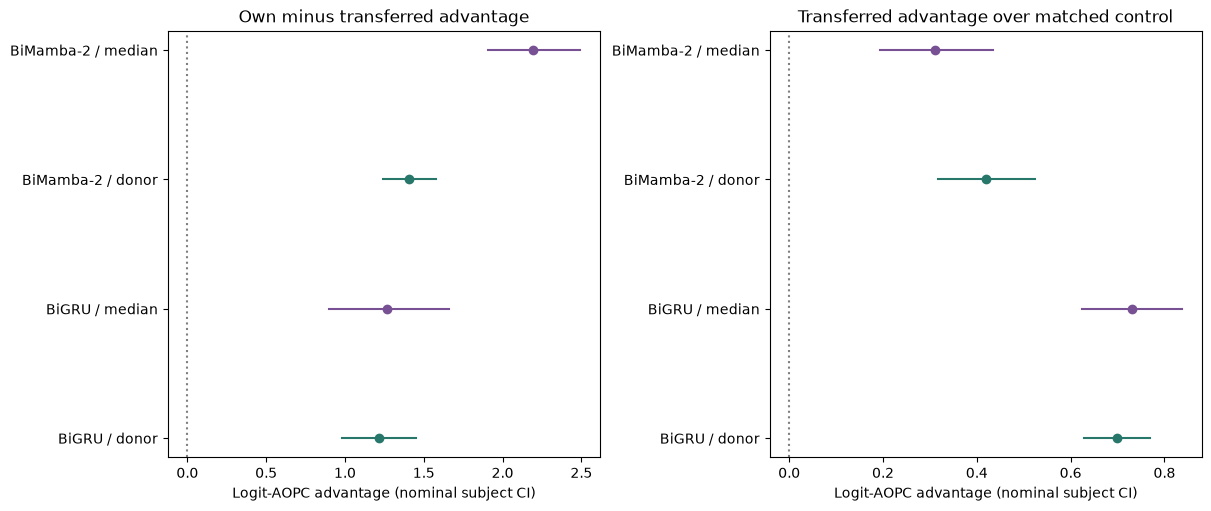

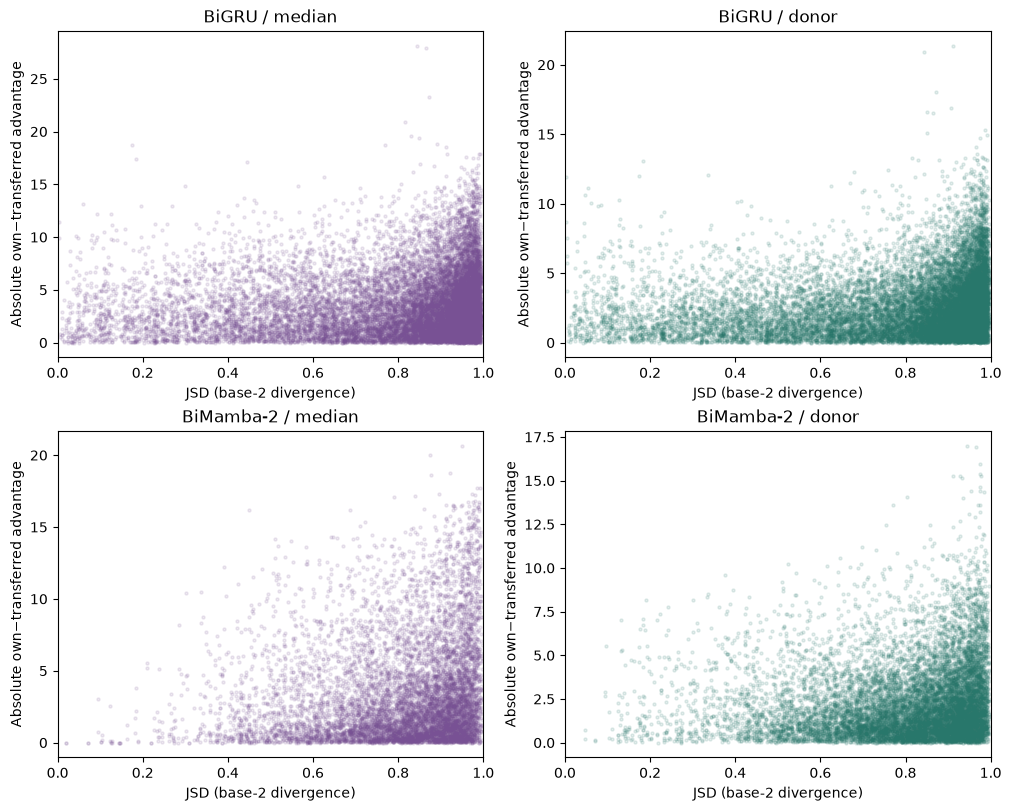

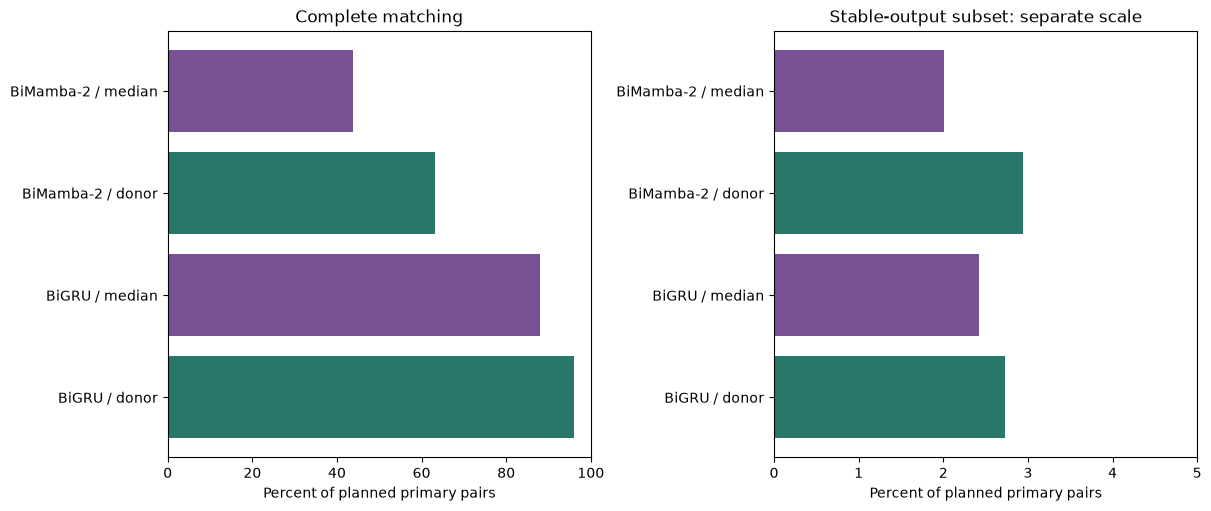

COMPLETE: /home/agribychaniago/Python Projects/Skripsi/results/attention_replication20_resume/newhandpd/9f048349d216342f9280825fa3e12dea0fbcb8eeeac3387efccead22f3b540f5/5b4141580bb4d3e8c061bd977968b4c2b8b02576195373a7e75db771f89ab53b/0082ecd5671e689ea2325bb0d45ed2ecfdffd7622ebc487e2edbbc2b0def0726
Source schedule, raw failures, nested record caches, and checkpoint identities retained.


In [15]:
labels={'gru':'BiGRU','mamba2':'BiMamba-2'}
colors={'train_median':'#785194','train_donor':'#28776b'}
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for j,endpoint in enumerate(('D','G_swap')):
    table=tables['primary_mean_D_unadjusted.csv'] if endpoint=='D' else tables['secondary_mean_contrasts.csv']
    if endpoint!='D':table=table.loc[(table.endpoint==endpoint)&(table.scenario=='all_primary')]
    for i,r in enumerate(table.itertuples(index=False)):
        axes[j].plot(r.estimate,i,'o',color=colors[r.masker])
        if np.isfinite(r.ci_low):axes[j].plot([r.ci_low,r.ci_high],[i,i],color=colors[r.masker])
    axes[j].set_yticks(range(len(table)),[labels[r.architecture]+' / '+r.masker.replace('train_','') for r in table.itertuples(index=False)])
    axes[j].axvline(0,color='.5',ls=':');axes[j].set_xlabel('Logit-AOPC advantage (nominal subject CI)')
    axes[j].set_title('Own minus transferred advantage' if endpoint=='D' else 'Transferred advantage over matched control')
savefig(fig,'ranking_transfer_replication')
fig,axes=plt.subplots(2,2,figsize=(10,8),layout='constrained')
for i,arm in enumerate(ARMS):
    for j,masker in enumerate(MASKERS):
        g=pair_curves.loc[pair_curves.primary_pair&pair_curves.pair_eligible&(pair_curves.architecture==arm)&(pair_curves.masker==masker)]
        axes[i,j].scatter(g.js_divergence,g.abs_D,s=5,alpha=.12,rasterized=True,color=colors[masker])
        axes[i,j].set(xlim=(0,1),xlabel='JSD (base-2 divergence)',ylabel='Absolute own−transferred advantage',
                      title=labels[arm]+' / '+masker.replace('train_',''))
savefig(fig,'jsd_absolute_swap_replication')
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
cov=tables['matching_coverage.csv']
for i,r in enumerate(cov.itertuples(index=False)):
    axes[0].barh(i,100*r.n_pairs_eligible/r.n_pairs_planned,color=colors[r.masker])
    axes[1].barh(i,100*r.n_stable_eligible/r.n_pairs_planned,color=colors[r.masker])
for ax in axes:ax.set_yticks(range(len(cov)),[labels[r.architecture]+' / '+r.masker.replace('train_','') for r in cov.itertuples(index=False)])
axes[0].set(xlim=(0,100),xlabel='Percent of planned primary pairs',title='Complete matching')
max_stable=max((100*r.n_stable_eligible/r.n_pairs_planned for r in cov.itertuples(index=False)),default=0)
axes[1].set(xlim=(0,max(5,max_stable*1.3)),xlabel='Percent of planned primary pairs',title='Stable-output subset: separate scale')
savefig(fig,'matching_and_stable_coverage')

# Finish only after every fixed target was trained/loaded and every planned row exists.
for relative,pinned_sha256 in EXECUTION_LOCK['source_sha256'].items():
    if file_sha256(ROOT/relative)!=pinned_sha256:
        raise AlignmentError('execution source changed mid-run: '+relative)
for relative,pinned_sha256 in LOCK['inputs'].items():
    if file_sha256(ROOT/relative)!=pinned_sha256:raise AlignmentError('protected input/source changed: '+relative)
if file_sha256(PLAN/'PROTOCOL.md')!=LOCK['protocol_sha256']:raise AlignmentError('protocol changed mid-run')
if notebook_code_digest(NOTEBOOK)!=SCIENTIFIC_SOURCE_DIGEST:
    raise AlignmentError('notebook scientific code changed during execution')
alignment=pd.DataFrame([
    dict(check='exact_200_checkpoint_identities',passed=len(models)==200 and not models.duplicated(['architecture','seed','fold']).any()),
    dict(check='one_OOF_map_per_architecture_seed_record',passed=len(predictions)==len(records)*40 and not predictions.duplicated(['architecture','seed','record_id']).any()),
    dict(check='all_planned_pair_replacement_rows_retained',passed=len(pair_curves)==expected and not pair_curves.duplicated(keys).any()),
    dict(check='all_defined_self_swaps_exact_zero',passed=bool((self_checks.loc[self_checks.defined,'D']==0).all())),
    dict(check='newhandpd_primary_excludes_discovery_seeds',passed=COHORT!='newhandpd' or bool(((pair_curves.loc[pair_curves.primary_pair,'target_seed']>=3)&(pair_curves.loc[pair_curves.primary_pair,'source_seed']>=3)).all())),
    dict(check='all_training_test_subject_sets_disjoint',passed=all(not(set(records.subject.iloc[a])&set(records.subject.iloc[b])) for a,b in splits)),
])
if not alignment.passed.all():raise AlignmentError('final alignment check failed')
atomic_csv(OUT/'alignment_checks.csv',alignment)
manifest.update(completion_status='complete',completed_utc=datetime.now(timezone.utc).isoformat(),
    n_checkpoints=len(models),n_records=len(records),n_subjects=records.subject.nunique(),
    primary_training_seeds=list(range(3,20)) if COHORT=='newhandpd' else list(range(20)),
    pooled_training_seeds=list(range(20)),
    inference='subject conditional on trained bank/split/schedule/matching; seed diagnostics separate',
    tables=sorted(p.name for p in OUT.glob('*.csv')),
    figures=sorted(p.name for p in FIG.glob('*')),
    scientific_source_sha256=SCIENTIFIC_SOURCE_DIGEST,
    result_sha256={p.name:file_sha256(p) for p in OUT.glob('*.csv')},
    bank_contains_new_training=True,
    new_checkpoint_target=170 if COHORT=='newhandpd' else 200,
    models_trained_this_session=int(models.trained_now.sum()),
    checkpoint_resume_unit='complete_fold; not mid_epoch',execution_id=EXECUTION_ID,
    fast_backend_profile_sha256=file_sha256(OUT/'fast_backend_profile.json'),
    fast_backend_choices=FAST_PROFILE['choices'],backend_validation_pending=False)
atomic_json(OUT/'analysis_manifest.json',manifest)
atomic_json(OUT/'sessions'/('complete_'+SESSION+'.json'),manifest)
flush_reuse_registry()
atomic_json(FAST_ROOT/COHORT/'latest_complete.json',
            dict(path=str(OUT.relative_to(ROOT)),design_id=DESIGN_ID,runtime_id=RUNTIME_ID,
                 manifest_sha256=file_sha256(OUT/'analysis_manifest.json')))
print('COMPLETE:',OUT)
print('Source schedule, raw failures, nested record caches, and checkpoint identities retained.')